In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

# NLP & Clustering Libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# CSV load karein
df = pd.read_csv(r"E:\excel class\netflix_titles.csv")

# Shape aur top 5 rows check karein
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (8812, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# Missing values ko empty string se fill karein
text_cols = ['director', 'cast', 'country', 'rating', 'listed_in', 'description']
for col in text_cols:
    df[col] = df[col].fillna('')

# Saare key text features ko ek sath jodein
df['combined_features'] = (
    df['listed_in'] + ' ' + 
    df['description'] + ' ' + 
    df['cast'] + ' ' + 
    df['director']
)

# Text cleaning function (punctuation aur extra spaces hatane ke liye)
def clean_text(text):
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_features'] = df['combined_features'].apply(clean_text)

# Check cleaned sample
df[['title', 'cleaned_features']].head()

,title,cleaned_features
0,Dick Johnson Is Dead,documentaries as her father nears the end of h...
1,Blood & Water,international tv shows tv dramas tv mysteries ...
2,Ganglands,crime tv shows international tv shows tv actio...
3,Jailbirds New Orleans,docuseries reality tv feuds flirtations and to...
4,Kota Factory,international tv shows romantic tv shows tv co...


In [4]:
# Text ko numbers me convert karein
tfidf = TfidfVectorizer(stop_words='english', max_features=3500)
X = tfidf.fit_transform(df['cleaned_features'])

print("TF-IDF Matrix Shape:", X.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

TF-IDF Matrix Shape: (8812, 3500)
Vocabulary size: 3500


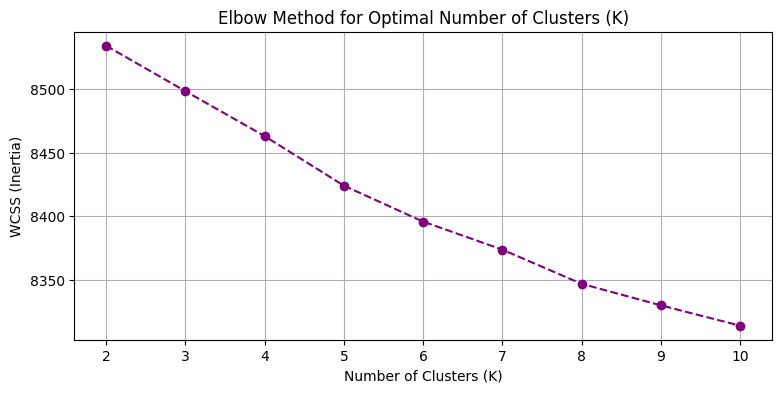

In [5]:
wcss = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=5)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Elbow Graph Plot karein
plt.figure(figsize=(9, 4))
plt.plot(k_range, wcss, marker='o', color='purple', linestyle='--')
plt.title('Elbow Method for Optimal Number of Clusters (K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

In [6]:
# K-Means model define & train karein (k=6)
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans.fit_predict(X)

# Cluster distribution check karein (har cluster me kitni movies hain)
print("Movies per Cluster:")
print(df['kmeans_cluster'].value_counts())

Movies per Cluster:
kmeans_cluster
1    3193
0    2488
5    1644
3     883
2     393
4     211
Name: count, dtype: int64


In [7]:
# Har cluster ki sample movies aur top themes dekhein
for c in range(optimal_k):
    print(f"\n{'='*20} CLUSTER {c} {'='*20}")
    sample_movies = df[df['kmeans_cluster'] == c][['title', 'listed_in']].head(4)
    for idx, row in sample_movies.iterrows():
        print(f"• {row['title']} -> ({row['listed_in']})")


==================== CLUSTER 0 ====================
• Sankofa -> (Dramas, Independent Movies, International Movies)
• Je Suis Karl -> (Dramas, International Movies)
• Avvai Shanmughi -> (Comedies, International Movies)
• Jeans -> (Comedies, International Movies, Romantic Movies)

==================== CLUSTER 1 ====================
• Midnight Mass -> (TV Dramas, TV Horror, TV Mysteries)
• My Little Pony: A New Generation -> (Children & Family Movies)
• The Starling -> (Comedies, Dramas)
• Confessions of an Invisible Girl -> (Children & Family Movies, Comedies)

==================== CLUSTER 2 ====================
• Lokillo: Nothing's the Same -> (Stand-Up Comedy)
• The Original Kings of Comedy -> (Stand-Up Comedy)
• Plastic Cup Boyz: Laughing My Mask Off! -> (Stand-Up Comedy & Talk Shows, TV Comedies)
• The Stand-Up -> (Stand-Up Comedy)

==================== CLUSTER 3 ====================
• Dick Johnson Is Dead -> (Documentaries)
• Europe's Most Dangerous Man: Otto Skorzeny in Spain -> 

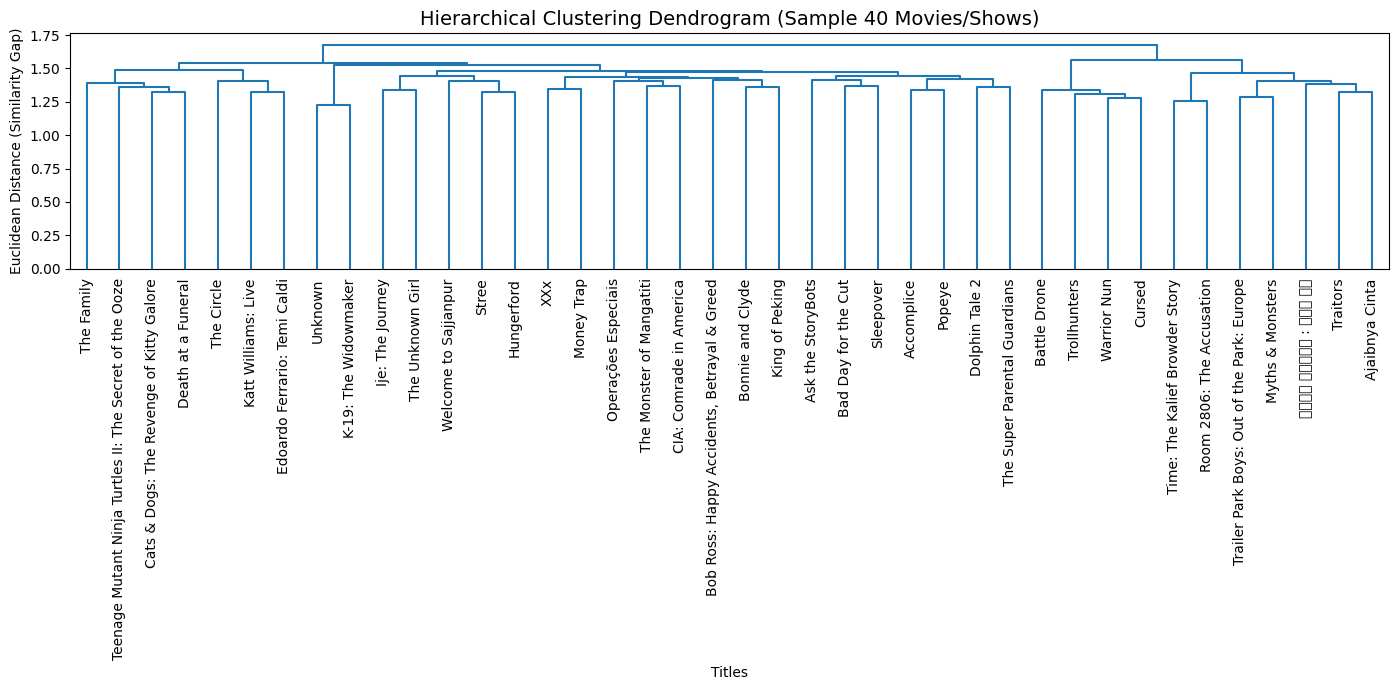

In [8]:
# Dendrogram visualize karne ke liye 40 sample movies le rahe hain
sample_subset = df.sample(n=40, random_state=42)
X_sub = tfidf.transform(sample_subset['cleaned_features']).toarray()

# Ward linkage se tree structure calculate karein
linked = linkage(X_sub, method='ward')

# Dendrogram Plot karein
plt.figure(figsize=(14, 7))
dendrogram(
    linked,
    labels=sample_subset['title'].values,
    leaf_rotation=90,
    leaf_font_size=10
)
plt.title('Hierarchical Clustering Dendrogram (Sample 40 Movies/Shows)', fontsize=14)
plt.xlabel('Titles')
plt.ylabel('Euclidean Distance (Similarity Gap)')
plt.tight_layout()
plt.show()

In [9]:
# 6 clusters ke sath Agglomerative model fit karein
agg = AgglomerativeClustering(n_clusters=6, metric='euclidean', linkage='ward')
sample_subset['agg_cluster'] = agg.fit_predict(X_sub)

print("Agglomerative Clusters assigned successfully to sample!")
sample_subset[['title', 'listed_in', 'agg_cluster']].head(6)

Agglomerative Clusters assigned successfully to sample!


,title,listed_in,agg_cluster
3969,Traitors,"British TV Shows, International TV Shows, TV D...",1
6433,Cats & Dogs: The Revenge of Kitty Galore,"Children & Family Movies, Comedies",2
6358,Bonnie and Clyde,"Action & Adventure, Classic Movies, Dramas",0
221,"Bob Ross: Happy Accidents, Betrayal & Greed",Documentaries,0
8766,XXx,"Action & Adventure, Sports Movies",0
3934,Time: The Kalief Browder Story,Docuseries,1


In [10]:
from sklearn.metrics.pairwise import cosine_similarity

# Har movie ke beech similarity score calculate karein
cosine_sim = cosine_similarity(X, X)

# Title se index dhoondhne ke liye mapping series
indices = pd.Series(df.index, index=df['title'].str.lower()).drop_duplicates()

def recommend_movies(title, num_recommendations=5):
    title_clean = title.strip().lower()
    
    if title_clean not in indices:
        return f"Movie '{title}' dataset me nahi mili. Kripya doosra naam try karein."
    
    # Target movie ka index nikalein
    idx = indices[title_clean]
    if isinstance(idx, pd.Series):
        idx = idx.iloc[0]
        
    # Similarity scores nikalein
    sim_scores = list(enumerate(cosine_sim[idx]))
    
    # Scores ke hisaab se sort karein (descending)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    # Top similar movies (pehle index ko chhodkar kyunki wo wahi movie hogi)
    sim_scores = sim_scores[1:num_recommendations+1]
    
    movie_indices = [i[0] for i in sim_scores]
    
    # Result display karein
    result = df[['title', 'listed_in', 'kmeans_cluster']].iloc[movie_indices].copy()
    result['Similarity_Score'] = [round(score[1] * 100, 2) for score in sim_scores]
    return result

# Test run karein
print("Recommendation Model Ready!")

Recommendation Model Ready!


In [11]:
# Ek movie test karein (Jaise: 'Blood & Water' ya dataset ki koi bhi movie)
test_title = df['title'].iloc[0]
print(f"Top 5 Recommendations for: '{test_title}'\n")
recommend_movies(test_title)

Top 5 Recommendations for: 'Dick Johnson Is Dead'



,title,listed_in,kmeans_cluster,Similarity_Score
2350,Woodshock,"Dramas, Independent Movies, Thrillers",1,27.39
7015,How to Be a Player,Comedies,1,24.94
3927,New Girl,"Romantic TV Shows, TV Comedies",5,19.37
6553,Daffedar,"Dramas, International Movies",0,19.07
7454,Midnight Special,"Action & Adventure, Sci-Fi & Fantasy",1,18.44


In [12]:
# Ek movie test karein (Jaise: 'Blood & Water' ya dataset ki koi bhi movie)
test_title = df['title'].iloc[0]
print(f"Top 5 Recommendations for: '{test_title}'\n")
recommend_movies(test_title)

Top 5 Recommendations for: 'Dick Johnson Is Dead'



,title,listed_in,kmeans_cluster,Similarity_Score
2350,Woodshock,"Dramas, Independent Movies, Thrillers",1,27.39
7015,How to Be a Player,Comedies,1,24.94
3927,New Girl,"Romantic TV Shows, TV Comedies",5,19.37
6553,Daffedar,"Dramas, International Movies",0,19.07
7454,Midnight Special,"Action & Adventure, Sci-Fi & Fantasy",1,18.44


In [13]:
import pickle

# Streamlit ke liye zaroori data export karein
app_data = {
    'df': df[['title', 'listed_in', 'description', 'kmeans_cluster']],
    'cosine_sim': cosine_sim
}

with open('netflix_data.pkl', 'wb') as f:
    pickle.dump(app_data, f)

print("Project Data Exported Successfully as netflix_data.pkl!")

Project Data Exported Successfully as netflix_data.pkl!


In [14]:
%%writefile C:\Users\Dell\netflix_app.py
import html
import random
import pickle
import pandas as pd
import streamlit as st
import requests
import urllib.parse

st.set_page_config(
    page_title="Netflix Movie Recommender",
    page_icon="🎬",
    layout="wide"
)

# ---------------- NETFLIX STYLE CSS WITH BUTTON CLICK ANIMATIONS ----------------
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Bebas+Neue&display=swap');

#MainMenu, footer, header { visibility: hidden; }
[data-testid="stAppViewContainer"] { background: #141414; }
.block-container { max-width: 1250px; padding-top: 1rem !important; }
label, [data-testid="stWidgetLabel"] p { color: #e5e5e5 !important; font-weight: 600; }

.navbar {
    display: flex; justify-content: space-between; align-items: center;
    padding: 12px 8px 18px 8px; border-bottom: 1px solid #2a2a2a; margin-bottom: 18px;
}
.logo {
    font-family: 'Bebas Neue', Impact, sans-serif; color: #E50914;
    font-size: 2.6rem; letter-spacing: 4px; line-height: 1;
    text-shadow: 0 0 18px rgba(229, 9, 20, 0.45);
}
.nav-right span {
    display: inline-block; margin-left: 8px; padding: 5px 12px; border-radius: 999px;
    background: rgba(255,255,255,0.08); border: 1px solid #333;
    color: #d2d2d2; font-size: 0.8rem;
}

.hero {
    border-radius: 16px; padding: 45px 40px; margin-bottom: 26px; min-height: 280px;
    display: flex; flex-direction: column; justify-content: center;
    box-shadow: 0 10px 40px rgba(0,0,0,0.6);
}
.hero-tag { color: #E50914; font-weight: 700; letter-spacing: 2px; font-size: 0.85rem; }
.hero-title {
    font-family: 'Bebas Neue', Impact, sans-serif; color: #fff;
    font-size: 3.2rem; line-height: 1.05; margin: 6px 0 10px 0; max-width: 700px;
}
.hero-desc { color: #d2d2d2; max-width: 620px; font-size: 0.95rem; line-height: 1.5; margin-bottom: 16px; }

/* 🌟 KEYFRAMES FOR BUTTON CLICK PULSE GLOW 🌟 */
@keyframes netflixPulse {
    0% {
        box-shadow: 0 0 0 0 rgba(229, 9, 20, 0.85);
    }
    70% {
        box-shadow: 0 0 0 16px rgba(229, 9, 20, 0);
    }
    100% {
        box-shadow: 0 0 0 0 rgba(229, 9, 20, 0);
    }
}

/* Base styling for Streamlit buttons */
.stButton > button {
    border-radius: 8px !important;
    font-weight: 700 !important;
    border: 1px solid #444 !important;
    background: #222 !important;
    color: #fff !important;
    transition: all 0.25s ease-in-out !important;
    position: relative;
    overflow: visible;
}

.stButton > button:hover {
    border-color: #E50914 !important;
    color: #E50914 !important;
    transform: translateY(-2px);
    box-shadow: 0 4px 15px rgba(229, 9, 20, 0.35) !important;
}

/* Button Active / Click Animation */
.stButton > button:active, .stButton > button:focus {
    transform: scale(0.96) !important;
    animation: netflixPulse 0.55s ease-out !important;
}

/* Primary Button (Get Similar Titles) */
[data-testid="stBaseButton-primary"], .stButton > button[kind="primary"] {
    background: #E50914 !important;
    border: none !important;
    color: #fff !important;
    box-shadow: 0 4px 14px rgba(229, 9, 20, 0.4) !important;
}

[data-testid="stBaseButton-primary"]:hover {
    background: #b20710 !important;
    box-shadow: 0 6px 20px rgba(229, 9, 20, 0.6) !important;
}

/* Trailer Buttons with Click Glow */
.trailer-btn, .card-trailer-btn {
    display: inline-block;
    background: #E50914;
    color: #fff !important;
    text-decoration: none;
    border-radius: 6px;
    font-weight: 700;
    text-align: center;
    transition: all 0.25s ease-in-out;
    box-shadow: 0 4px 12px rgba(229, 9, 20, 0.4);
}

.trailer-btn {
    padding: 10px 24px;
    font-size: 0.95rem;
}

.card-trailer-btn {
    width: 100%;
    padding: 7px;
    font-size: 0.85rem;
}

.trailer-btn:hover, .card-trailer-btn:hover {
    transform: translateY(-2px);
    box-shadow: 0 6px 18px rgba(229, 9, 20, 0.65);
    background: #ff1e27;
}

.trailer-btn:active, .card-trailer-btn:active {
    transform: scale(0.95);
    animation: netflixPulse 0.5s ease-out;
}

.match-text {
    color: #46d369 !important;
    font-weight: 700;
    font-size: 0.95rem;
    margin: 4px 0;
}
</style>
""", unsafe_allow_html=True)

# OMDb API Key
OMDB_API_KEY = "5ae6b180"

@st.cache_data(show_spinner=False)
def get_movie_poster(title):
    try:
        url = f"http://www.omdbapi.com/?t={title}&apikey={OMDB_API_KEY}"
        data = requests.get(url, timeout=4).json()
        poster = data.get('Poster')
        if poster and poster != "N/A":
            return poster
    except:
        pass
    return "https://dummyimage.com/300x450/141414/ffffff&text=No+Poster"

@st.cache_resource
def load_data():
    with open(r'C:\Users\Dell\netflix_data.pkl', 'rb') as f:
        data = pickle.load(f)
    return data['df'], data['cosine_sim']

df, cosine_sim = load_data()
movie_list = df['title'].values

def get_recommendations(selected_title):
    idx = df[df['title'] == selected_title].index[0]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:6]
    recs = df.iloc[[i for i, _ in sim_scores]].copy()
    recs['match'] = [int(round(s * 100)) for _, s in sim_scores]
    return recs

# ---------------- NAVBAR ----------------
st.markdown(
    '<div class="navbar">'
    '<div class="logo">NETFLIX</div>'
    '<div class="nav-right">'
    f'<span>📚 {len(df):,} titles</span>'
    f'<span>🧩 {df["kmeans_cluster"].nunique()} clusters</span>'
    '<span>🤖 K-Means + Cosine Similarity</span>'
    '</div></div>',
    unsafe_allow_html=True
)

hero_slot = st.empty()

# ---------------- CONTROLS ----------------
c1, c2, c3 = st.columns([1, 2, 1])
with c2:
    selected_movie = st.selectbox("🔎 Search or select a Movie / TV Show", movie_list)
    b1, b2 = st.columns(2)
    show_btn = b1.button("🔍 Get Similar Titles", use_container_width=True, type="primary")
    surprise_btn = b2.button("🎲 Surprise Me", use_container_width=True)

target = None
if surprise_btn:
    target = random.choice(list(movie_list))
    st.toast(f"Surprise pick: {target}", icon="🎲")
elif show_btn:
    target = selected_movie

# ---------------- HERO BANNER ----------------
if target is None:
    hero_slot.markdown(
        '<div class="hero" style="background:linear-gradient(to right,rgba(20,20,20,0.95) 35%,rgba(20,20,20,0.3)),'
        'radial-gradient(circle at 80% 30%,#b20710,#141414 70%)">'
        '<div class="hero-tag">🍿 PERSONALISED FOR YOU</div>'
        '<div class="hero-title">Unlimited movies, shows and recommendations.</div>'
        '<div class="hero-desc">Select any title above to view its trailer and find similar recommendations.</div></div>',
        unsafe_allow_html=True
    )
else:
    trow = df[df['title'] == target].iloc[0]
    hero_poster = get_movie_poster(trow['title'])
    target_trailer_query = urllib.parse.quote(f"{trow['title']} official trailer")
    target_trailer_url = f"https://www.youtube.com/results?search_query={target_trailer_query}"
    
    hero_slot.markdown(
        f'<div class="hero" style="background:linear-gradient(to right, rgba(20,20,20,0.95) 40%, rgba(20,20,20,0.35)), url(\'{hero_poster}\') right center/contain no-repeat, #1f1f1f">'
        f'<div class="hero-tag">🎬 SELECTED TITLE</div>'
        f'<div class="hero-title">{html.escape(trow["title"])}</div>'
        f'<div class="hero-desc">{html.escape(trow["description"])}</div>'
        f'<div><a class="trailer-btn" href="{target_trailer_url}" target="_blank">▶ Watch Trailer</a></div>'
        '</div>',
        unsafe_allow_html=True
    )

    # ---------------- RECOMMENDATIONS ROW ----------------
    recs = get_recommendations(target)
    st.markdown('<h3 style="color:#fff; margin-top:20px;">🔥 Top 5 Recommended Titles</h3>', unsafe_allow_html=True)
    
    cols = st.columns(5)
    for i, (_, row) in enumerate(recs.iterrows()):
        with cols[i]:
            poster_url = get_movie_poster(row['title'])
            st.image(poster_url, use_container_width=True)
            st.markdown(f"**🍿 {row['title']}**")
            st.markdown(f"<div class='match-text'>🎯 {row['match']}% Match</div>", unsafe_allow_html=True)
            st.caption(f"🧩 Cluster #{row['kmeans_cluster']} · _{row['listed_in'][:30]}..._")
            
            with st.expander("📖 Story"):
                st.write(row['description'])
                
            with st.expander("▶ Watch Trailer"):
                query = urllib.parse.quote(f"{row['title']} official trailer")
                trailer_search_url = f"https://www.youtube.com/results?search_query={query}"
                st.markdown(
                    f"<a class='card-trailer-btn' href='{trailer_search_url}' target='_blank'>▶ Play Trailer</a>",
                    unsafe_allow_html=True
                )

st.markdown(
    '<div style="text-align:center; color:#777; margin-top:40px; font-size:0.8rem;">'
    '🛠️ Built with Streamlit · Netflix Machine Learning Recommendation System</div>',
    unsafe_allow_html=True
)

Overwriting C:\Users\Dell\netflix_app.py


In [15]:
import os
print(os.path.abspath("netflix_app.py"))

C:\Users\Dell\Ai-ML Project\netflix_app.py


In [16]:
import pickle
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# CSV load karein
csv_path = r"E:\excel class\netflix_titles.csv"
df = pd.read_csv(csv_path)

# Missing values fill
df['director'] = df['director'].fillna('')
df['cast'] = df['cast'].fillna('')
df['listed_in'] = df['listed_in'].fillna('')
df['description'] = df['description'].fillna('')
df['rating'] = df['rating'].fillna('Not Rated')
df['type'] = df['type'].fillna('Movie')
df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce').fillna(2020).astype(int)

# Feature engineering
df['director_clean'] = df['director'].apply(lambda x: ' '.join([i.replace(' ', '') for i in x.split(',')]))
df['cast_clean'] = df['cast'].apply(lambda x: ' '.join([i.replace(' ', '') for i in x.split(',')[:3]]))
df['listed_clean'] = df['listed_in'].apply(lambda x: x.replace('&', '').replace(',', ' '))
df['desc_clean'] = df['description']

df['rich_features'] = (
    df['director_clean'] + ' ' + df['director_clean'] + ' ' +
    df['cast_clean'] + ' ' + df['cast_clean'] + ' ' +
    df['listed_clean'] + ' ' + df['listed_clean'] + ' ' +
    df['desc_clean']
)

# TF-IDF & Cosine Similarity
tfidf_adv = TfidfVectorizer(stop_words='english', max_features=3500)
X_adv = tfidf_adv.fit_transform(df['rich_features'])
cosine_sim_adv = cosine_similarity(X_adv, X_adv)

# K-Means
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans.fit_predict(X_adv)

# PCA 2D
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_adv.toarray())
df['pca_x'] = pca_coords[:, 0]
df['pca_y'] = pca_coords[:, 1]

# Pickle save
pkl_path = r"C:\Users\Dell\netflix_data.pkl"
app_data = {
    'df': df[['title', 'type', 'listed_in', 'description', 'release_year', 'rating', 'cast', 'director', 'kmeans_cluster', 'pca_x', 'pca_y']],
    'cosine_sim': cosine_sim_adv
}

with open(pkl_path, 'wb') as f:
    pickle.dump(app_data, f)

print("Columns in saved data:", list(app_data['df'].columns))

Columns in saved data: ['title', 'type', 'listed_in', 'description', 'release_year', 'rating', 'cast', 'director', 'kmeans_cluster', 'pca_x', 'pca_y']


In [17]:
%%writefile C:\Users\Dell\netflix_app.py
import difflib
import hashlib
import hmac
import html
import json
import os
import pickle
import random
import re
import secrets
import threading
import time
import urllib.parse
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import plotly.express as px
import requests
import streamlit as st
import streamlit.components.v1 as components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

st.set_page_config(
    page_title="Netflix ML Hub",
    page_icon="🎬",
    layout="wide",
    initial_sidebar_state="collapsed"
)

# ---------------- API KEYS (read from environment variables) ----------------
OMDB_API_KEY = os.getenv("OMDB_API_KEY", "")
TMDB_API_KEY = os.getenv("TMDB_API_KEY", "")
NO_POSTER = "__no_poster__"                          # internal marker (shows the black poster)

# ---------------- FILES (inside the project folder) ----------------
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
CACHE_FILE = os.path.join(BASE_DIR, "poster_cache.json")
DATA_FILE = os.path.join(BASE_DIR, "netflix_data.pkl")
USERS_FILE = os.path.join(BASE_DIR, "users.json")

# ---------------- STREAMING REGIONS ----------------
REGIONS = ["IN", "US", "GB", "CA", "AU"]
REGION_NAMES = {"IN": "India", "US": "United States", "GB": "United Kingdom", "CA": "Canada", "AU": "Australia"}

# ---------------- USERS + PER-USER WATCHLIST ----------------
USERNAME_RE = re.compile(r"[a-z0-9_.-]{3,20}")

def _hash_password(password, salt_hex):
    return hashlib.pbkdf2_hmac("sha256", password.encode("utf-8"), bytes.fromhex(salt_hex), 200_000).hex()

def load_users():
    if os.path.exists(USERS_FILE):
        try:
            with open(USERS_FILE, 'r', encoding='utf-8') as f:
                return json.load(f)
        except Exception:
            return {}
    return {}

def save_users(users):
    try:
        with open(USERS_FILE, 'w', encoding='utf-8') as f:
            json.dump(users, f, ensure_ascii=False, indent=2)
    except Exception as e:
        st.error(f"Could not save user: {e}")

def create_user(username, password):
    username = username.strip().lower()
    if not USERNAME_RE.fullmatch(username):
        return False, "Username must be 3-20 characters: letters, numbers, dot, underscore or dash."
    if len(password) < 6:
        return False, "Password must be at least 6 characters."
    users = load_users()
    if username in users:
        return False, "This username is already taken."
    salt = secrets.token_hex(16)
    users[username] = {"salt": salt, "hash": _hash_password(password, salt)}
    save_users(users)
    return True, username

def check_login(username, password):
    """Returns 'ok', 'no_user' or 'bad_pass'."""
    users = load_users()
    rec = users.get(username.strip().lower())
    if not rec:
        return "no_user"
    if hmac.compare_digest(rec["hash"], _hash_password(password, rec["salt"])):
        return "ok"
    return "bad_pass"

def watchlist_file():
    user = st.session_state.get("user")
    return os.path.join(BASE_DIR, f"watchlist_{user}.json") if user else None

def load_watchlist_from_disk():
    path = watchlist_file()
    if path and os.path.exists(path):
        try:
            with open(path, 'r', encoding='utf-8') as f:
                return json.load(f)
        except Exception:
            return []
    return []

def save_watchlist_to_disk(watchlist_data):
    path = watchlist_file()
    if not path:
        return
    try:
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(watchlist_data, f, ensure_ascii=False, indent=2)
    except Exception as e:
        st.error(f"Save error: {e}")

def start_session(username):
    st.session_state.user = username
    st.session_state.watchlist = load_watchlist_from_disk()
    st.session_state.target_movie = None
    st.session_state.ai_query = None
    st.rerun()

def logout():
    st.session_state.user = None
    st.session_state.watchlist = []
    st.session_state.target_movie = None
    st.session_state.ai_query = None
    st.session_state.ai_input_box = ""

if 'user' not in st.session_state:
    st.session_state.user = None
if 'watchlist' not in st.session_state:
    st.session_state.watchlist = []
if 'target_movie' not in st.session_state:
    st.session_state.target_movie = None
if 'ai_query' not in st.session_state:
    st.session_state.ai_query = None
if 'show_intro' not in st.session_state:
    st.session_state.show_intro = True
if 'go_home_tab' not in st.session_state:
    st.session_state.go_home_tab = False

# reset the pending (background loading) counter on every run
st.session_state["_pending"] = 0

# ---------------- NETFLIX + MOBILE FRIENDLY CSS ----------------
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Bebas+Neue&display=swap');

#MainMenu, footer, header { visibility: hidden; }
[data-testid="stAppViewContainer"] { background: #141414; }
.block-container { max-width: 1280px; padding-top: 1rem !important; }
label, [data-testid="stWidgetLabel"] p { color: #e5e5e5 !important; font-weight: 600; }
[data-testid="stMarkdownContainer"], [data-testid="stMarkdownContainer"] p,
[data-testid="stCaptionContainer"], [data-testid="stCaptionContainer"] p,
h1, h2, h3, h4 { color: #e5e5e5; }
[data-testid="stCaptionContainer"] p { color: #a8a8a8 !important; }

/* Hide the fullscreen button on images (posters) */
button[title="View fullscreen"],
[data-testid="StyledFullScreenButton"],
[data-testid="stImage"] button,
[data-testid="stImageContainer"] button { display: none !important; }

/* ---------- LOGIN SCREEN ---------- */
.login-logo {
    font-family: 'Bebas Neue', Impact, sans-serif; color: #E50914; text-align: center;
    font-size: 4rem; letter-spacing: 6px; line-height: 1; margin-top: 30px;
    text-shadow: 0 0 22px rgba(229, 9, 20, 0.5);
}
.login-sub { text-align: center; color: #bdbdbd; margin: 8px 0 18px 0; font-size: 0.95rem; }

/* ---------- STREAMING / RATING INFO ---------- */
.meta-line { color: #d2d2d2; font-size: 0.85rem; margin: 3px 0; }
.meta-line a { color: #f5c518 !important; text-decoration: none; font-weight: 700; }
.prov-row { display: flex; align-items: center; gap: 6px; flex-wrap: wrap; margin: 5px 0; }
.prov-label { color: #9a9a9a; font-size: 0.72rem; min-width: 46px; }
.prov-logo { width: 26px; height: 26px; border-radius: 6px; object-fit: cover; }
.prov-chip { background: #2a2a2a; border-radius: 6px; padding: 2px 7px; font-size: 0.72rem; color: #ddd; }
.prov-none { color: #8a8a8a; font-size: 0.78rem; margin: 4px 0; }
.prov-link { font-size: 0.75rem; color: #E50914 !important; text-decoration: none; }

/* ---------- INTRO SPLASH ANIMATION ---------- */
@keyframes introOverlay {
    0%, 80% { opacity: 1; visibility: visible; }
    100%    { opacity: 0; visibility: hidden; display: none; }
}
@keyframes introLogo {
    0%   { transform: scale(0.5); opacity: 0; letter-spacing: 2px; filter: blur(10px); }
    22%  { opacity: 1; filter: blur(0); }
    62%  { transform: scale(1); letter-spacing: 14px; opacity: 1; }
    100% { transform: scale(8); letter-spacing: 34px; opacity: 0; }
}
@keyframes introGlow {
    0%, 100% { text-shadow: 0 0 20px rgba(229, 9, 20, 0.5); }
    50%      { text-shadow: 0 0 55px rgba(229, 9, 20, 1), 0 0 120px rgba(229, 9, 20, 0.6); }
}
@keyframes introSweep {
    0%   { transform: translateX(-100%); }
    100% { transform: translateX(170%); }
}
@keyframes introSub {
    0%, 20% { opacity: 0; transform: translateY(10px); }
    45%, 75% { opacity: 1; transform: translateY(0); }
    100% { opacity: 0; }
}
.intro-overlay {
    position: fixed; top: 0; left: 0; width: 100vw; height: 100vh; z-index: 99999;
    background: radial-gradient(circle at center, #1a0000 0%, #000 70%);
    display: flex; flex-direction: column; align-items: center; justify-content: center;
    animation: introOverlay 4.2s ease forwards; pointer-events: auto; cursor: pointer;
}
.intro-logo {
    font-family: 'Bebas Neue', Impact, sans-serif; color: #E50914;
    font-size: clamp(3.2rem, 15vw, 9rem); line-height: 1;
    animation: introLogo 3.8s cubic-bezier(.7, 0, .3, 1) forwards, introGlow 1.2s ease-in-out infinite;
}
.intro-bar {
    width: 240px; height: 3px; margin-top: 22px; border-radius: 3px;
    background: #2a2a2a; overflow: hidden;
}
.intro-bar span {
    display: block; width: 60%; height: 100%; background: #E50914;
    animation: introSweep 1.2s ease-in-out infinite;
}
.intro-sub {
    margin-top: 16px; color: #bdbdbd; letter-spacing: 3px; font-size: 0.85rem;
    animation: introSub 4s ease forwards;
}
.intro-hint {
    margin-top: 10px; color: #9a9a9a; font-size: 0.8rem; letter-spacing: 1px;
    animation: introSub 4s ease forwards;
}

/* NAVBAR LOGO FIX (Native Button Styling) */
div[data-testid="stHorizontalBlock"]:has(.logo-marker) {
    border-bottom: 1px solid #2a2a2a;
    padding-bottom: 10px;
    margin-bottom: 15px;
    align-items: center;
}
div[data-testid="stColumn"]:has(.logo-marker) [data-testid="stButton"] button {
    background: transparent !important;
    border: none !important;
    padding: 0 !important;
    box-shadow: none !important;
    min-height: auto !important;
}
div[data-testid="stColumn"]:has(.logo-marker) [data-testid="stButton"] button p {
    font-family: 'Bebas Neue', Impact, sans-serif !important;
    color: #E50914 !important;
    font-size: 2.6rem !important;
    letter-spacing: 4px !important;
    line-height: 1 !important;
    text-shadow: 0 0 18px rgba(229, 9, 20, 0.45) !important;
    margin: 0 !important;
}
div[data-testid="stColumn"]:has(.logo-marker) [data-testid="stButton"] button:hover p {
    text-shadow: 0 0 25px rgba(229, 9, 20, 0.7) !important;
    transform: scale(1.02);
    transition: all 0.2s ease;
}
.nav-right span {
    display: inline-block; padding: 5px 12px; border-radius: 999px;
    background: rgba(255,255,255,0.08); border: 1px solid #333;
    color: #d2d2d2; font-size: 0.8rem; white-space: nowrap; margin-bottom: 5px;
}

/* ---------- HERO CARD ---------- */
.st-key-hero_box {
    position: relative; overflow: hidden; border-radius: 16px;
    padding: 42px 40px 36px 40px; margin-bottom: 8px; min-height: 270px;
    justify-content: center; gap: 0.5rem;
    box-shadow: 0 10px 40px rgba(0,0,0,0.6);
    background: radial-gradient(circle at 80% 30%, #4a060b, #141414 70%);
}
.st-key-hero_box > div { max-width: 62%; }
.st-key-hero_box [data-testid="stHorizontalBlock"] { max-width: 400px; gap: 10px; }
.st-key-hero_box .stButton > button,
.st-key-hero_box [data-testid="stLinkButton"] a,
.st-key-hero_box a[data-testid^="stBaseLinkButton"] {
    min-height: 40px !important; font-size: 0.88rem !important; padding: 4px 10px !important;
}
.hero-tag { color: #E50914; font-weight: 700; letter-spacing: 2px; font-size: 0.85rem; }
.hero-title {
    font-family: 'Bebas Neue', Impact, sans-serif; color: #fff;
    font-size: 3.2rem; line-height: 1.05; margin: 6px 0 10px 0;
}
.hero-desc { color: #d2d2d2; font-size: 0.95rem; line-height: 1.5; margin-bottom: 25px; }

/* Buttons */
@keyframes netflixPulse {
    0% { box-shadow: 0 0 0 0 rgba(229, 9, 20, 0.85); }
    70% { box-shadow: 0 0 0 14px rgba(229, 9, 20, 0); }
    100% { box-shadow: 0 0 0 0 rgba(229, 9, 20, 0); }
}
.stButton > button {
    border-radius: 8px !important; font-weight: 700 !important; min-height: 46px;
    border: 1px solid #444 !important; background: #222 !important; color: #fff !important;
    transition: all 0.25s ease !important;
}
.stButton > button:hover {
    border-color: #E50914 !important; color: #E50914 !important;
    transform: translateY(-2px); box-shadow: 0 4px 15px rgba(229, 9, 20, 0.35) !important;
}
.stButton > button:active { transform: scale(0.96) !important; animation: netflixPulse 0.5s ease-out !important; }
[data-testid="stBaseButton-primary"], .stButton > button[kind="primary"] {
    background: #E50914 !important; border: none !important; color: #fff !important;
}

[data-testid="stLinkButton"] a, a[data-testid^="stBaseLinkButton"] {
    background: #E50914 !important; border: none !important; border-radius: 8px !important;
    min-height: 46px; display: flex !important; align-items: center; justify-content: center;
    text-decoration: none !important; font-weight: 700 !important;
    transition: all 0.25s ease !important; box-shadow: 0 4px 12px rgba(229, 9, 20, 0.4);
}
[data-testid="stLinkButton"] a:hover, a[data-testid^="stBaseLinkButton"]:hover {
    background: #ff1e27 !important; transform: translateY(-2px);
}
[data-testid="stLinkButton"] a p, a[data-testid^="stBaseLinkButton"] p { color: #fff !important; }

div[data-testid="stElementContainer"]:has(.action-marker),
div.element-container:has(.action-marker) { display: none; }

.trailer-btn, .card-trailer-btn {
    display: inline-block; background: #E50914; color: #fff !important;
    text-decoration: none !important; border-radius: 6px; font-weight: 700; text-align: center;
    transition: all 0.25s ease; box-shadow: 0 4px 12px rgba(229, 9, 20, 0.4);
}
.trailer-btn { padding: 11px 24px; font-size: 0.95rem; }
.card-trailer-btn { display: block; width: 100%; padding: 10px 0; font-size: 0.88rem; margin: 15px 0 8px 0; }
.trailer-btn:hover, .card-trailer-btn:hover { transform: translateY(-2px); background: #ff1e27; }
.match-text { color: #46d369 !important; font-weight: 700; font-size: 0.95rem; margin: 4px 0; }
.lock-pill {
    display: inline-block; padding: 4px 14px; border-radius: 999px; margin: 2px 0 12px 0;
    background: rgba(229, 9, 20, 0.15); border: 1px solid #E50914; color: #ffb3b8; font-size: 0.85rem;
}

div[data-baseweb="select"] > div {
    background: #262626 !important; border: 1px solid #444 !important; border-radius: 8px !important;
}
div[data-baseweb="select"] * { color: #fff !important; }
ul[role="listbox"] { background: #1f1f1f !important; }
[data-testid="stExpander"] { background: #1b1b1b; border: 1px solid #2c2c2c !important; border-radius: 10px; }
[data-testid="stExpander"] summary p { color: #fff !important; font-weight: 600; }
button[data-baseweb="tab"] p { color: #bdbdbd !important; font-weight: 600; }
button[data-baseweb="tab"][aria-selected="true"] p { color: #E50914 !important; }

div[data-testid="stHorizontalBlock"]:has(.rec-marker) > div[data-testid="stColumn"],
div[data-testid="stHorizontalBlock"]:has(.rec-marker) > div[data-testid="column"] {
    background: #1b1b1b; border: 1px solid #2c2c2c; border-radius: 14px; padding: 10px;
    transition: transform 0.3s ease, box-shadow 0.3s ease;
}
div[data-testid="stHorizontalBlock"]:has(.rec-marker) > div[data-testid="stColumn"]:hover,
div[data-testid="stHorizontalBlock"]:has(.rec-marker) > div[data-testid="column"]:hover {
    transform: translateY(-4px); box-shadow: 0 12px 28px rgba(229, 9, 20, 0.3);
}
.swipe-hint { display: none; color: #9a9a9a; font-size: 0.85rem; margin: 2px 0 8px 2px; }

div[data-testid="stButton"]:has(button[key^="play_"]) { margin-top: 15px; }

/* Dashboard Charts Customization */
.js-plotly-plot .plotly .main-svg { border-radius: 12px; }

/* ---------- MOOD BUTTONS ---------- */
div[data-testid="stElementContainer"]:has(.mood-marker),
div.element-container:has(.mood-marker) { display: none; }
div[data-testid="stHorizontalBlock"]:has(.mood-marker) { gap: 8px !important; margin-top: 4px; }
div[data-testid="stHorizontalBlock"]:has(.mood-marker) .stButton > button {
    min-height: 40px; border-radius: 999px !important; font-size: 0.85rem !important;
}

@media (max-width: 768px) {
    .block-container { padding-left: 0.8rem !important; padding-right: 0.8rem !important; }
    .st-key-hero_box { padding: 26px 18px 22px 18px; min-height: 230px; }
    .st-key-hero_box > div { max-width: 100%; }
    .st-key-hero_box [data-testid="stHorizontalBlock"] { max-width: 100%; }
    .hero-title { font-size: 2.2rem; }
    .swipe-hint { display: block; }

    div[data-testid="stHorizontalBlock"]:has(.action-marker) { flex-wrap: nowrap !important; gap: 10px !important; }
    div[data-testid="stHorizontalBlock"]:has(.action-marker) > div[data-testid="stColumn"],
    div[data-testid="stHorizontalBlock"]:has(.action-marker) > div[data-testid="column"] {
        flex: 1 1 0 !important; min-width: 0 !important; width: auto !important;
    }

    div[data-testid="stHorizontalBlock"]:has(.rec-marker) {
        flex-wrap: nowrap !important; overflow-x: auto !important; gap: 14px !important;
        scroll-snap-type: x mandatory; padding-bottom: 12px; -webkit-overflow-scrolling: touch;
    }
    div[data-testid="stHorizontalBlock"]:has(.rec-marker) > div[data-testid="stColumn"],
    div[data-testid="stHorizontalBlock"]:has(.rec-marker) > div[data-testid="column"] {
        flex: 0 0 215px !important; min-width: 215px !important; width: 215px !important;
        scroll-snap-align: start;
    }

    div[data-testid="stHorizontalBlock"]:has(.mood-marker) {
        flex-wrap: nowrap !important; overflow-x: auto !important; padding-bottom: 8px;
        -webkit-overflow-scrolling: touch;
    }
    div[data-testid="stHorizontalBlock"]:has(.mood-marker) > div[data-testid="stColumn"],
    div[data-testid="stHorizontalBlock"]:has(.mood-marker) > div[data-testid="column"] {
        flex: 0 0 auto !important; min-width: 140px !important; width: auto !important;
    }
}
</style>
""", unsafe_allow_html=True)

# ---------------- INTRO SOUND (injected into the page, plays on first tap) ----------------
SOUND_CODE = r"""
(function () {
  if (window.__nfxSoundInstalled) { return; }
  window.__nfxSoundInstalled = true;
  var START = Date.now();
  var played = false;
  var IMPACT = 2.3;
  var ctx = null;
  var AC = window.AudioContext || window.webkitAudioContext;
  if (!AC) { return; }
  var EVENTS = ["touchend", "pointerup", "mousedown", "click", "keydown"];

  function whoosh(master, at, dur) {
    var len = Math.floor(ctx.sampleRate * (dur + 0.25));
    var buf = ctx.createBuffer(1, len, ctx.sampleRate);
    var d = buf.getChannelData(0);
    for (var i = 0; i < len; i++) { d[i] = Math.random() * 2 - 1; }
    var src = ctx.createBufferSource(); src.buffer = buf;
    var bp = ctx.createBiquadFilter(); bp.type = "bandpass"; bp.Q.value = 0.9;
    bp.frequency.setValueAtTime(220, at);
    bp.frequency.exponentialRampToValueAtTime(4200, at + dur);
    var g = ctx.createGain();
    g.gain.setValueAtTime(0.0001, at);
    g.gain.exponentialRampToValueAtTime(0.26, at + dur * 0.92);
    g.gain.exponentialRampToValueAtTime(0.0001, at + dur + 0.15);
    src.connect(bp); bp.connect(g); g.connect(master);
    src.start(at); src.stop(at + dur + 0.25);
  }

  function pad(master, at, notes, lead) {
    var total = lead + 2.0;
    var lp = ctx.createBiquadFilter();
    lp.type = "lowpass"; lp.Q.value = 0.8;
    lp.frequency.setValueAtTime(250, at);
    lp.frequency.exponentialRampToValueAtTime(3200, at + lead);
    lp.frequency.exponentialRampToValueAtTime(800, at + total);
    var g = ctx.createGain();
    g.gain.setValueAtTime(0.0001, at);
    g.gain.exponentialRampToValueAtTime(0.18, at + lead);
    g.gain.exponentialRampToValueAtTime(0.0001, at + total);
    lp.connect(g); g.connect(master);
    notes.forEach(function (f) {
      [-7, 7].forEach(function (det) {
        var o = ctx.createOscillator(), og = ctx.createGain();
        o.type = "sawtooth"; o.frequency.value = f; o.detune.value = det;
        og.gain.value = 0.1;
        o.connect(og); og.connect(lp);
        o.start(at); o.stop(at + total + 0.1);
      });
    });
  }

  function boom(master, at) {
    var o = ctx.createOscillator(), g = ctx.createGain();
    o.type = "sine";
    o.frequency.setValueAtTime(110, at);
    o.frequency.exponentialRampToValueAtTime(36, at + 1.6);
    g.gain.setValueAtTime(0.0001, at);
    g.gain.exponentialRampToValueAtTime(1.0, at + 0.02);
    g.gain.exponentialRampToValueAtTime(0.0001, at + 2.2);
    o.connect(g); g.connect(master);
    o.start(at); o.stop(at + 2.3);
  }

  function bell(master, at, f, vol, dur) {
    [[1, 1, 1], [2.76, 0.4, 0.55], [5.4, 0.18, 0.35], [8.93, 0.08, 0.22]].forEach(function (p) {
      var freq = f * p[0];
      if (freq > 12000) { return; }
      var o = ctx.createOscillator(), g = ctx.createGain();
      o.type = "sine"; o.frequency.value = freq;
      g.gain.setValueAtTime(0.0001, at);
      g.gain.exponentialRampToValueAtTime(vol * p[1], at + 0.012);
      g.gain.exponentialRampToValueAtTime(0.0001, at + dur * p[2]);
      o.connect(g); g.connect(master);
      o.start(at); o.stop(at + dur * p[2] + 0.05);
    });
  }

  function playSound(elapsed) {
    var t = ctx.currentTime + 0.05;
    var lead = Math.max(0.35, IMPACT - elapsed);
    var master = ctx.createGain(); master.gain.value = 0.85;
    var comp = ctx.createDynamicsCompressor();
    master.connect(comp); comp.connect(ctx.destination);

    whoosh(master, t, lead);
    pad(master, t, [146.83, 220, 293.66, 369.99, 440, 659.25], lead);
    boom(master, t + lead);
    bell(master, t + lead, 587.33, 0.24, 2.4);
    [739.99, 880, 1174.66, 1479.98, 1760].forEach(function (f, i) {
      bell(master, t + lead + 0.14 + i * 0.11, f, 0.11, 1.9);
    });
  }

  function removeListeners() {
    EVENTS.forEach(function (ev) { document.removeEventListener(ev, tryPlay, true); });
  }

  function tryPlay() {
    if (played) { return; }
    var elapsed = (Date.now() - START) / 1000;
    if (elapsed > 15) { removeListeners(); return; }
    try { if (!ctx) { ctx = new AC(); } } catch (e) { return; }
    var go = function () {
      if (played || !ctx || ctx.state !== "running") { return; }
      played = true;
      removeListeners();
      playSound((Date.now() - START) / 1000);
    };
    try {
      var p = ctx.resume();
      if (p && p.then) { p.then(go).catch(function () {}); } else { go(); }
    } catch (e) {}
  }

  EVENTS.forEach(function (ev) { document.addEventListener(ev, tryPlay, true); });
})();
"""

if st.session_state.show_intro:
    st.session_state.show_intro = False
    st.markdown(
        '<div class="intro-overlay">'
        '<div class="intro-logo">NETFLIX</div>'
        '<div class="intro-bar"><span></span></div>'
        '<div class="intro-sub">🎬 ML RECOMMENDATION HUB</div>'
        '<div class="intro-hint">🔊 Tap anywhere for sound</div>'
        '</div>',
        unsafe_allow_html=True
    )
    components.html(
        "<script>(function(){var code=" + json.dumps(SOUND_CODE) + ";"
        "try{var p=window.parent;var s=p.document.createElement('script');"
        "s.textContent=code;p.document.head.appendChild(s);}"
        "catch(e){try{(new Function(code))();}catch(e2){}}})();</script>",
        height=0
    )

# ---------------- LOGIN / SIGN UP SCREEN (shown until the user is logged in) ----------------
if not st.session_state.user:
    _l, _mid, _r = st.columns([1, 1.4, 1])
    with _mid:
        st.markdown('<div class="login-logo">NETFLIX</div><div class="login-sub">Sign in to continue</div>', unsafe_allow_html=True)
        tab_in, tab_up = st.tabs(["🔑 Login", "📝 Sign Up"])

        with tab_in:
            with st.form("login_form"):
                li_user = st.text_input("Username", key="li_user")
                li_pass = st.text_input("Password", type="password", key="li_pass")
                li_submit = st.form_submit_button("Login", use_container_width=True, type="primary")
            if li_submit:
                status = check_login(li_user, li_pass)
                if status == "ok":
                    start_session(li_user.strip().lower())
                elif status == "no_user":
                    st.error("No account found with this username. Please create one in the Sign Up tab first.")
                else:
                    time.sleep(1)   # slow down repeated wrong guesses
                    st.error("Wrong password. Please try again.")
            st.caption(f"Accounts file: {USERS_FILE}")   # debugging help: remove this line once login works

        with tab_up:
            with st.form("signup_form"):
                su_user = st.text_input("Choose a username", key="su_user")
                su_pass = st.text_input("Choose a password", type="password", key="su_pass")
                su_pass2 = st.text_input("Confirm password", type="password", key="su_pass2")
                su_submit = st.form_submit_button("Create account", use_container_width=True, type="primary")
            if su_submit:
                if su_pass != su_pass2:
                    st.error("Passwords do not match.")
                else:
                    ok, msg = create_user(su_user, su_pass)
                    if ok:
                        start_session(msg)
                    else:
                        st.error(msg)
    st.stop()

# ---------------- DATA LOADING & AI MODEL ----------------
@st.cache_resource
def load_data():
    with open(DATA_FILE, 'rb') as f:
        data = pickle.load(f)
    return data['df'], data['cosine_sim']

df, cosine_sim = load_data()
movie_list = df['title'].values

@st.cache_resource
def build_ai_search_model(_dataframe):
    dataframe = _dataframe
    tfidf = TfidfVectorizer(stop_words='english')
    # Repeat the title 3 times so searching by movie name works well
    text_data = (dataframe['title'].fillna('') + " ").str.repeat(3) \
        + dataframe['description'].fillna('') + " " + dataframe['listed_in'].fillna('')
    for col in ('cast', 'director', 'country'):
        if col in dataframe.columns:
            text_data = text_data + " " + dataframe[col].fillna('')
    matrix = tfidf.fit_transform(text_data)
    return tfidf, matrix

tfidf_model, tfidf_matrix = build_ai_search_model(df)

@st.cache_resource
def build_info(_dataframe):
    info = {}
    for t, y, ty in zip(_dataframe['title'], _dataframe['release_year'], _dataframe['type']):
        if t not in info:
            try: yy = int(y)
            except Exception: yy = None
            info[t] = (yy, "tv" if ty == "TV Show" else "movie")
    return info

INFO = build_info(df)

# ---------------- NO POSTER (black poster) ----------------
@st.cache_resource
def get_no_poster_img():
    try:
        from PIL import Image, ImageDraw, ImageFont
        W, H = 300, 450
        img = Image.new("RGB", (W, H), (0, 0, 0))
        d = ImageDraw.Draw(img)
        d.rectangle([10, 10, W - 11, H - 11], outline=(229, 9, 20), width=3)
        try:
            font = ImageFont.truetype("arialbd.ttf", 34)
            small = ImageFont.truetype("arial.ttf", 16)
        except Exception:
            try:
                font = ImageFont.load_default(size=34)
                small = ImageFont.load_default(size=16)
            except Exception:
                font = ImageFont.load_default()
                small = font
        for text, y, fnt, col in (("NO POSTER", H // 2 - 22, font, (229, 9, 20)),
                                  ("Not available", H // 2 + 28, small, (150, 150, 150))):
            box = d.textbbox((0, 0), text, font=fnt)
            d.text(((W - (box[2] - box[0])) / 2, y), text, font=fnt, fill=col)
        return img
    except Exception:
        return "https://dummyimage.com/300x450/000000/e50914&text=No+Poster"

NO_POSTER_IMG = get_no_poster_img()

def show_poster(url):
    if not url or url == NO_POSTER:
        st.image(NO_POSTER_IMG, use_container_width=True)
    else:
        st.image(url, use_container_width=True)

# ---------------- POSTER + TRAILER + EXTRA INFO ENGINE (background threads + disk cache) ----------------
POSTER_HEADERS = {"User-Agent": "NetflixMLHub/1.0 (student project)"}
FAIL_TTL = 600                 # seconds (a failed lookup is not retried for 10 minutes)
EXTRA_TTL = 7 * 24 * 3600      # seconds (IMDb / streaming info is refreshed after 7 days)

@st.cache_resource
def get_store_v3():
    store = {"poster": {}, "trailer": {}, "extra": {}, "fail": {}, "pending": set(), "tmdb_down": False,
             "lock": threading.Lock(), "http": requests.Session(),
             "pool": ThreadPoolExecutor(max_workers=8)}
    adapter = requests.adapters.HTTPAdapter(pool_connections=64, pool_maxsize=64)
    store["http"].mount("https://", adapter)
    store["http"].mount("http://", adapter)
    if os.path.exists(CACHE_FILE):
        try:
            with open(CACHE_FILE, 'r', encoding='utf-8') as f:
                saved = json.load(f)
            store["poster"].update(saved.get("poster", {}))
            store["trailer"].update(saved.get("trailer", {}))
            store["extra"].update(saved.get("extra", {}))
        except Exception:
            pass
    return store

STORE = get_store_v3()
HTTP = STORE["http"]

def save_cache():
    with STORE["lock"]:
        try:
            with open(CACHE_FILE, 'w', encoding='utf-8') as f:
                json.dump({"poster": STORE["poster"], "trailer": STORE["trailer"], "extra": STORE["extra"]}, f, ensure_ascii=False)
        except Exception:
            pass

def _norm(s):
    s = re.sub(r"[(].*?[)]", " ", str(s).lower())
    s = re.sub(r"[^a-z0-9 ]+", " ", s)
    return " ".join(s.split())

def _similar(a, b):
    return difflib.SequenceMatcher(None, _norm(a), _norm(b)).ratio()

def _image_ok(url):
    try:
        r = HTTP.get(url, stream=True, headers=POSTER_HEADERS, timeout=(2, 3))
        ok = r.status_code == 200 and "image" in r.headers.get("content-type", "").lower()
        r.close()
        return ok
    except Exception:
        return False

def _poster_tmdb(name, kind, year):
    if not TMDB_API_KEY or STORE["tmdb_down"]: return None
    year_key = "first_air_date_year" if kind == "tv" else "year"
    for path, extra in ((kind, {year_key: year} if year else {}), ("multi", {})):
        try:
            res = HTTP.get(f"https://api.themoviedb.org/3/search/{path}", params={"api_key": TMDB_API_KEY, "query": name, **extra}, timeout=(2, 3)).json()
            for item in res.get("results", [])[:5]:
                if item.get("poster_path"): return "https://image.tmdb.org/t/p/w500" + item["poster_path"]
        except (requests.ConnectionError, requests.Timeout):
            STORE["tmdb_down"] = True   # TMDB is unreachable -> don't retry in this session
            return None
        except Exception: pass
    return None

def _poster_omdb(name, kind, year):
    if not OMDB_API_KEY: return None
    otype = "series" if kind == "tv" else "movie"
    for extra in ({"y": year, "type": otype} if year else {"type": otype}, {}):
        try:
            data = HTTP.get("https://www.omdbapi.com/", params={"t": name, "apikey": OMDB_API_KEY, **extra}, timeout=(2, 3)).json()
            poster = data.get("Poster")
            if poster and poster != "N/A": return poster
        except Exception: pass
    return None

def _poster_itunes(name, kind, year):
    for country in ("US", "IN"):
        try:
            res = HTTP.get("https://itunes.apple.com/search", params={"term": name, "media": "tvShow" if kind == "tv" else "movie", "entity": "tvSeason" if kind == "tv" else "movie", "country": country, "limit": 10}, headers=POSTER_HEADERS, timeout=(2, 3)).json()
            for item in res.get("results", []):
                if kind == "tv":
                    found = re.sub(r",?[ \t]*(Season|Series|Book)[ \t]*[0-9]+.*$", "", item.get("collectionName", ""), flags=re.I)
                else:
                    found = item.get("trackName", "")
                    rel = str(item.get("releaseDate", ""))[:4]
                    if year and rel.isdigit() and abs(int(rel) - year) > 1: continue
                if _similar(found, name) < 0.85: continue
                art = item.get("artworkUrl100")
                if art: return re.sub(r"[0-9]+x[0-9]+bb", "600x900bb", art)
        except Exception: pass
    return None

def _poster_tvmaze(name, kind, year):
    if kind != "tv": return None
    try:
        r = HTTP.get("https://api.tvmaze.com/singlesearch/shows", params={"q": name}, timeout=(2, 3))
        if r.status_code == 200:
            js = r.json()
            if _similar(js.get("name", ""), name) >= 0.8:
                img = js.get("image") or {}
                return img.get("original") or img.get("medium")
    except Exception: pass
    return None

def _poster_wikipedia(name, kind, year):
    label = "television series" if kind == "tv" else "film"
    queries = [f"{name} {year} {label}", f"{name} {label}"] if year else [f"{name} {label}"]
    for q in queries:
        try:
            res = HTTP.get("https://en.wikipedia.org/w/api.php", params={"action": "query", "generator": "search", "gsrsearch": q, "gsrlimit": 3, "prop": "pageimages", "piprop": "thumbnail", "pithumbsize": 500, "format": "json"}, headers=POSTER_HEADERS, timeout=(2, 3)).json()
            pages = sorted(res.get("query", {}).get("pages", {}).values(), key=lambda p: p.get("index", 99))
            for p in pages:
                thumb = (p.get("thumbnail") or {}).get("source")
                if thumb and _similar(p.get("title", ""), name) >= 0.8: return thumb
        except Exception: pass
    return None

POSTER_SOURCES = (_poster_tmdb, _poster_omdb, _poster_itunes, _poster_tvmaze, _poster_wikipedia)

def fetch_poster(title, year, kind):
    names = [title]
    cleaned = re.sub(r"\s*[(].*?[)]", "", title).strip()
    if cleaned and cleaned != title: names.append(cleaned)
    for name in names:
        ex = ThreadPoolExecutor(max_workers=len(POSTER_SOURCES))
        try:
            futs = [(src, ex.submit(src, name, kind, year)) for src in POSTER_SOURCES]
            for src, f in futs:   # priority order, but all sources run in parallel
                try: url = f.result()
                except Exception: url = None
                if not url: continue
                if src is _poster_omdb and not _image_ok(url): continue   # OMDb links are sometimes broken
                return url
        finally:
            ex.shutdown(wait=False, cancel_futures=True)
    return None

def get_poster_cached(title):
    year, kind = INFO.get(title, (None, "movie"))
    key = f"{title}|{year}"
    url = STORE["poster"].get(key)
    if url: return url
    t = STORE["fail"].get("p|" + key)
    if t and time.time() - t < FAIL_TTL: return NO_POSTER
    url = fetch_poster(title, year, kind)
    if url:
        STORE["poster"][key] = url
        save_cache()
        return url
    STORE["fail"]["p|" + key] = time.time()
    return NO_POSTER

def peek_poster(title):
    year, _ = INFO.get(title, (None, "movie"))
    return STORE["poster"].get(f"{title}|{year}") or NO_POSTER

# ---------------- TRAILER ----------------
def youtube_search_url(title): return "https://www.youtube.com/results?search_query=" + urllib.parse.quote(f"{title} official trailer")

def fetch_trailer(title, year):
    if TMDB_API_KEY and not STORE["tmdb_down"]:
        try:
            res = HTTP.get("https://api.themoviedb.org/3/search/multi", params={"api_key": TMDB_API_KEY, "query": title}, timeout=(2, 3)).json()
            for item in res.get("results", [])[:3]:
                if item.get("media_type") not in ("movie", "tv"): continue
                vids = HTTP.get(f"https://api.themoviedb.org/3/{item['media_type']}/{item['id']}/videos", params={"api_key": TMDB_API_KEY}, timeout=(2, 3)).json().get("results", [])
                vids = [v for v in vids if v.get("site") == "YouTube"]
                vids.sort(key=lambda v: (v.get("type") != "Trailer", not v.get("official", False)))
                if vids: return f"https://www.youtube.com/watch?v={vids[0]['key']}"
        except (requests.ConnectionError, requests.Timeout):
            STORE["tmdb_down"] = True
        except Exception: pass
    try:
        query = f"{title} {year} official trailer" if year else f"{title} official trailer"
        resp = HTTP.get("https://www.youtube.com/results", params={"search_query": query}, headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36", "Accept-Language": "en-US,en;q=0.9"}, cookies={"CONSENT": "YES+1"}, timeout=(2, 5))
        ids = re.findall(r'"videoId":"([A-Za-z0-9_-]{11})"', resp.text)
        if ids: return f"https://www.youtube.com/watch?v={ids[0]}"
    except Exception: pass
    return None

def get_trailer_cached(title):
    year, _ = INFO.get(title, (None, "movie"))
    key = f"{title}|{year}"
    url = STORE["trailer"].get(key)
    if url: return url
    t = STORE["fail"].get("t|" + key)
    if t and time.time() - t < FAIL_TTL: return youtube_search_url(title)
    url = fetch_trailer(title, year)
    if url:
        STORE["trailer"][key] = url
        save_cache()
        return url
    STORE["fail"]["t|" + key] = time.time()
    return youtube_search_url(title)

def peek_trailer(title):
    year, _ = INFO.get(title, (None, "movie"))
    return STORE["trailer"].get(f"{title}|{year}") or youtube_search_url(title)

# ---------------- EXTRA INFO: IMDb rating + runtime (OMDb) and where to watch (TMDB / JustWatch) ----------------
def _extra_omdb(title, year, kind):
    if not OMDB_API_KEY: return {}
    otype = "series" if kind == "tv" else "movie"
    for extra in ({"y": year, "type": otype} if year else {"type": otype}, {}):
        try:
            d = HTTP.get("https://www.omdbapi.com/", params={"t": title, "apikey": OMDB_API_KEY, **extra}, timeout=(2, 3)).json()
            if d.get("Response") == "True":
                out = {"imdb": d.get("imdbRating"), "runtime": d.get("Runtime"), "imdb_id": d.get("imdbID")}
                return {k: v for k, v in out.items() if v and v != "N/A"}
        except Exception: pass
    return {}

def _extra_tmdb(title, year, kind):
    if not TMDB_API_KEY or STORE["tmdb_down"]: return {}
    year_key = "first_air_date_year" if kind == "tv" else "year"
    tmdb_id = None
    for extra in ({year_key: year} if year else {}, {}):
        try:
            res = HTTP.get(f"https://api.themoviedb.org/3/search/{kind}", params={"api_key": TMDB_API_KEY, "query": title, **extra}, timeout=(2, 3)).json()
            results = res.get("results", [])[:5]
            if results:
                best = max(results, key=lambda it: _similar(it.get("title") or it.get("name") or "", title))
                if _similar(best.get("title") or best.get("name") or "", title) >= 0.6:
                    tmdb_id = best["id"]
                    break
        except (requests.ConnectionError, requests.Timeout):
            STORE["tmdb_down"] = True
            return {}
        except Exception: pass
    if not tmdb_id: return {}
    try:
        data = HTTP.get(f"https://api.themoviedb.org/3/{kind}/{tmdb_id}/watch/providers", params={"api_key": TMDB_API_KEY}, timeout=(2, 3)).json()
    except (requests.ConnectionError, requests.Timeout):
        STORE["tmdb_down"] = True
        return {}
    except Exception:
        return {}
    results = data.get("results") or {}
    providers = {}
    for reg in REGIONS:
        r = results.get(reg)
        if not r: continue
        entry = {"link": r.get("link")}
        for key in ("flatrate", "free", "ads", "rent", "buy"):
            entry[key] = [[p.get("provider_name", ""), p.get("logo_path") or ""] for p in (r.get(key) or [])[:6]]
        providers[reg] = entry
    return {"providers": providers}

def fetch_extra(title, year, kind):
    out = {}
    with ThreadPoolExecutor(max_workers=2) as ex:
        futs = [ex.submit(_extra_omdb, title, year, kind), ex.submit(_extra_tmdb, title, year, kind)]
        for f in futs:
            try: out.update(f.result())
            except Exception: pass
    return out

def get_extra_cached(title):
    year, kind = INFO.get(title, (None, "movie"))
    key = f"{title}|{year}"
    cached = STORE["extra"].get(key)
    if cached and time.time() - cached.get("ts", 0) < EXTRA_TTL: return cached
    t = STORE["fail"].get("e|" + key)
    if t and time.time() - t < FAIL_TTL: return cached or {}
    data = fetch_extra(title, year, kind)
    if data:
        data["ts"] = time.time()
        STORE["extra"][key] = data
        save_cache()
        return data
    STORE["fail"]["e|" + key] = time.time()
    return cached or {}

def peek_extra(title):
    year, _ = INFO.get(title, (None, "movie"))
    return STORE["extra"].get(f"{title}|{year}") or {}

def providers_html(prov, t, region):
    none_msg = f"<div class='prov-none'>{t['no_stream']} {html.escape(REGION_NAMES.get(region, region))}</div>"
    if not prov: return none_msg
    rows = ""
    for key in ("flatrate", "free", "ads", "rent", "buy"):
        items = prov.get(key) or []
        if not items: continue
        chips = ""
        for name, logo in items[:5]:
            n = html.escape(str(name), quote=True)
            if logo:
                chips += f"<img class='prov-logo' src='https://image.tmdb.org/t/p/w92{html.escape(str(logo), quote=True)}' title='{n}' alt='{n}'>"
            else:
                chips += f"<span class='prov-chip'>{n}</span>"
        rows += f"<div class='prov-row'><span class='prov-label'>{t['p_' + key]}</span>{chips}</div>"
    if not rows: return none_msg
    link = prov.get("link")
    if link and str(link).startswith("http"):
        rows += f"<a class='prov-link' href='{html.escape(str(link), quote=True)}' target='_blank' rel='noopener noreferrer'>{t['all_options']}</a>"
    return rows

def extra_html(title, t, region):
    ex = peek_extra(title)
    if not ex: return ""
    bits = []
    imdb = ex.get("imdb")
    if imdb:
        label = f"⭐ {html.escape(str(imdb))} IMDb"
        imdb_id = str(ex.get("imdb_id") or "")
        if re.fullmatch(r"tt\d+", imdb_id):
            label = f"<a href='https://www.imdb.com/title/{imdb_id}/' target='_blank' rel='noopener noreferrer'>{label}</a>"
        bits.append(label)
    if ex.get("runtime"):
        bits.append(f"⏱️ {html.escape(str(ex['runtime']))}")
    out = f"<div class='meta-line'>{' · '.join(bits)}</div>" if bits else ""
    if "providers" in ex:
        out += providers_html(ex["providers"].get(region), t, region)
    return out

# ---------------- BACKGROUND QUEUE (does not block the page) ----------------
def _job_poster(title):
    try: get_poster_cached(title)
    except Exception: pass
    finally: STORE["pending"].discard("p|" + title)

def _job_trailer(title):
    try: get_trailer_cached(title)
    except Exception: pass
    finally: STORE["pending"].discard("t|" + title)

def _job_extra(title):
    try: get_extra_cached(title)
    except Exception: pass
    finally: STORE["pending"].discard("e|" + title)

def queue_posters(titles):
    """Fetch missing posters in the background. Returns how many are still loading."""
    n = 0
    for t in dict.fromkeys(titles):
        year, _ = INFO.get(t, (None, "movie"))
        key = f"{t}|{year}"
        if key in STORE["poster"]: continue
        ft = STORE["fail"].get("p|" + key)
        if ft and time.time() - ft < FAIL_TTL: continue
        tag = "p|" + t
        if tag not in STORE["pending"]:
            STORE["pending"].add(tag)
            STORE["pool"].submit(_job_poster, t)
        n += 1
    return n

def queue_trailers(titles):
    n = 0
    for t in dict.fromkeys(titles):
        year, _ = INFO.get(t, (None, "movie"))
        key = f"{t}|{year}"
        if key in STORE["trailer"]: continue
        ft = STORE["fail"].get("t|" + key)
        if ft and time.time() - ft < FAIL_TTL: continue
        tag = "t|" + t
        if tag not in STORE["pending"]:
            STORE["pending"].add(tag)
            STORE["pool"].submit(_job_trailer, t)
        n += 1
    return n

def queue_extras(titles):
    n = 0
    for t in dict.fromkeys(titles):
        year, _ = INFO.get(t, (None, "movie"))
        key = f"{t}|{year}"
        cached = STORE["extra"].get(key)
        if cached and time.time() - cached.get("ts", 0) < EXTRA_TTL: continue
        ft = STORE["fail"].get("e|" + key)
        if ft and time.time() - ft < FAIL_TTL: continue
        tag = "e|" + t
        if tag not in STORE["pending"]:
            STORE["pending"].add(tag)
            STORE["pool"].submit(_job_extra, t)
        n += 1
    return n

def is_direct(url): return "watch?v=" in url
def trailer_link(url, label, css_class): return f"<a class='{css_class}' href='{html.escape(url, quote=True)}' target='_blank' rel='noopener noreferrer'>{label}</a>"

def hero_style(poster):
    if not poster or poster == NO_POSTER: return ""
    p = str(poster).replace(chr(92), "%5C").replace('"', "%22").replace("<", "%3C")
    return f"<style>.st-key-hero_box{{background:linear-gradient(to right,rgba(20,20,20,0.97) 38%,rgba(20,20,20,0.3) 100%),url(\"{p}\") right center / auto 100% no-repeat,radial-gradient(circle at 80% 30%,#4a060b,#141414 70%) !important;}}@media (max-width:768px){{.st-key-hero_box{{background:linear-gradient(rgba(20,20,20,0.9),rgba(20,20,20,0.9)),url(\"{p}\") center / cover no-repeat,#141414 !important;}}}}</style>"

# ---------------- GENRE MATCHING ----------------
GENRE_KEYS = [("horror", "horror"), ("anime", "anime"), ("sci-fi", "scifi"), ("docu", "documentary"), ("stand-up", "standup"), ("children", "kids"), ("kids", "kids"), ("music", "music"), ("romantic", "romance"), ("crime", "crime"), ("mystery", "mystery"), ("thriller", "thriller"), ("action", "action"), ("comed", "comedy"), ("drama", "drama"), ("reality", "reality"), ("sport", "sports"), ("teen", "teen"), ("faith", "faith")]
TAG_LABEL = {"horror": "🧛 Horror", "anime": "🎌 Anime", "scifi": "🛸 Sci-Fi & Fantasy", "documentary": "🎞️ Documentary", "standup": "🎤 Stand-Up", "kids": "🧸 Kids & Family", "music": "🎸 Music", "romance": "💘 Romance", "crime": "🚨 Crime", "mystery": "🔮 Mystery", "thriller": "🕵️ Thriller", "action": "💥 Action & Adventure", "comedy": "🤣 Comedy", "drama": "🎭 Drama", "reality": "📡 Reality", "sports": "🏆 Sports", "teen": "🎒 Teen", "faith": "🕊️ Faith"}
GENRE_EMOJI = [("horror", "🧛"), ("sci-fi", "🛸"), ("fantasy", "🧙♂️"), ("anime", "🎌"), ("kids", "🧸"), ("comed", "🤣"), ("romantic", "💘"), ("action", "💥"), ("thriller", "🕵️"), ("crime", "🚨"), ("documentar", "🎞️"), ("music", "🎸"), ("stand-up", "🎤"), ("reality", "📡"), ("drama", "🎭"), ("international", "🌏"), ("sport", "🏆"), ("adventure", "🧭"), ("mystery", "🔮"), ("teen", "🎒"), ("classic", "📽️"), ("cult", "🌀"), ("faith", "🕊️"), ("lgbt", "🏳️🌈")]

def genre_tags(text):
    tags = set()
    for part in str(text).split(","):
        p = part.strip().lower()
        for key, tag in GENRE_KEYS:
            if key in p: tags.add(tag); break
    return tags

def main_genre(tags):
    for _, tag in GENRE_KEYS:
        if tag in tags: return tag
    return None

def genre_emoji(genres):
    g, found = str(genres).lower(), []
    for key, emo in GENRE_EMOJI:
        if key in g and emo not in found: found.append(emo)
        if len(found) == 2: break
    return "".join(found) if found else "🍿"

def match_badge(score): return "💎" if score >= 80 else "🔥" if score >= 60 else "✨" if score >= 40 else "🌱"
def type_emoji(t): return "🎬" if t == "Movie" else "📺"
def short(text, n=28): return str(text) if len(str(text)) <= n else str(text)[:n] + "…"

# ---------------- MULTI-LANGUAGE DICTIONARY ----------------
T = {
    "en": {
        "filters_title": "🎛️ Advanced Filters", "type_label": "🧭 Content Type Preference:",
        "type_auto": "🪄 Auto-match with Selected", "type_all": "🍿 All Types",
        "type_movie": "🎬 Only Movies", "type_tv": "📺 Only TV Shows / Series",
        "genre_label": "🎭 Genre Match:", "genre_strict": "🔒 Strict (same main genre)",
        "genre_flex": "🧩 Flexible (any shared genre)", "genre_off": "🌐 Off (all genres)",
        "genre_locked": "Genre lock:", "year_label": "🗓️ Release Year Range:",
        "match_label": "🎯 Min Match Score (%):", "region_label": "🌍 Streaming Region:",
        "saved_wl": "💖 Saved to Watchlist:",
        "clear_wl": "🧨 Clear All Saved Watchlist", "tab1": "🎞️ Recommender",
        "tab2": "🪐 Cluster Universe", "tab3": "💖 My Watchlist", "tab4": "📊 Taste Profile",
        "search_label": "🔍 Standard Search:", "get_recs": "🚀 Get Recommendations",
        "surprise": "🪄 Surprise Me", "surprise_toast": "🪄 Surprise Pick:",
        "ai_search_title": "🤖 AI (Smart Search)",
        "ai_search_prompt": "Describe your mood... (e.g., 'space travel comedy')",
        "ai_btn": "✨ Magic Search",
        "hero_tag_def": "✨ PERSONALISED FOR YOU", "hero_title_def": "Discover smart weighted content.",
        "hero_desc_def": "Same-type and same-genre matching: Horror recommends Horror, Comedy recommends Comedy.",
        "hero_tag_sel": "🎬 SELECTED TITLE", "play_trailer": "▶️ Watch Trailer",
        "play_here": "📺 Play trailer inside the app", "play_app": "📺 Play in App",
        "no_direct": "Direct video not found. Open the YouTube search instead:",
        "finding": "🛰️ Finding trailer...", "loading": "🔄 Loading posters... they will appear automatically.",
        "swipe": "👉 Swipe to explore more",
        "recs_for": "🔥 Top Recommendations for", "recs_sub": "Strictly matching same content type:",
        "ai_recs_for": "✨ Magic AI Results for:",
        "ai_no_match": "⚠️ No exact matches found for these words. Try different keywords like 'comedy', 'space', or 'action'.",
        "ai_year_info": "ℹ️ Showing results outside the selected year range.",
        "no_filter_match": "⚠️ No matching titles found! Try relaxing the filters.",
        "story": "📖 Story", "add_wl": "💖 Add to Watchlist", "in_wl": "✅ In Watchlist",
        "remove_wl": "🗑️ Remove", "added_toast": "💖 Saved to Watchlist:",
        "removed_toast": "🗑️ Removed from Watchlist:", "cluster_map_title": "🪐 Netflix 2D Clustering Space",
        "cluster_map_desc": "Interactive scatter map showing dimension reduction. Similar themes cluster together:",
        "scatter_title": "Content Distribution (2D Reduced Space)", "wl_title": "💖 Your Permanent Watchlist",
        "wl_empty": "Your watchlist is empty. Tap 💖 on any title to save it!", "dl_csv": "📥 Download CSV",
        "unlock_profile": "🔒 Add at least 3 titles to your watchlist to unlock your Taste Profile Analytics!",
        "p_flatrate": "Stream", "p_free": "Free", "p_ads": "Free+Ads", "p_rent": "Rent", "p_buy": "Buy",
        "no_stream": "🚫 No streaming info for", "all_options": "All options ↗",
        "cluster_names": {0: "🌏 International Dramas", 1: "🤣 Comedies & Romance", 2: "💥 Action & Thrillers", 3: "🧸 Kids & Animation", 4: "🎞️ Documentaries", 5: "🛸 TV Dramas & Sci-Fi"}
    },
    "hi": {
        "filters_title": "🎛️ एडवांस फिल्टर्स", "type_label": "🧭 कंटेंट टाइप चुनें:",
        "type_auto": "🪄 ऑटो-मैच (मूवी ➔ मूवी, सीरीज ➔ सीरीज)", "type_all": "🍿 सभी प्रकार (All)",
        "type_movie": "🎬 सिर्फ मूवीज़ (Movies)", "type_tv": "📺 सिर्फ सीरीज (TV Shows)",
        "genre_label": "🎭 जॉनर मैच:", "genre_strict": "🔒 सख्त (वही मुख्य जॉनर)",
        "genre_flex": "🧩 लचीला (कोई भी साझा जॉनर)", "genre_off": "🌐 बंद (सभी जॉनर)",
        "genre_locked": "जॉनर लॉक:", "year_label": "🗓️ रिलीज़ वर्ष सीमा:",
        "match_label": "🎯 न्यूनतम मैच प्रतिशत (%):", "region_label": "🌍 स्ट्रीमिंग क्षेत्र:",
        "saved_wl": "💖 वॉचलिस्ट में सेव:",
        "clear_wl": "🧨 पूरी वॉचलिस्ट खाली करें", "tab1": "🎞️ सिफारिश इंजन",
        "tab2": "🪐 क्लस्टर मैप", "tab3": "💖 मेरी वॉचलिस्ट", "tab4": "📊 मेरी पसंद (Profile)",
        "search_label": "🔍 स्टैंडर्ड सर्च:", "get_recs": "🚀 सिफारिशें देखें",
        "surprise": "🪄 मुझे हैरान करें", "surprise_toast": "🪄 सरप्राइज पसंद:",
        "ai_search_title": "🤖 AI (Smart Search)",
        "ai_search_prompt": "आप क्या देखना चाहते हैं? (जैसे: 'space travel comedy')",
        "ai_btn": "✨ मैजिक सर्च",
        "hero_tag_def": "✨ सिर्फ आपके लिए", "hero_title_def": "सटीक सेम-टाइप कंटेंट खोजें।",
        "hero_desc_def": "सेम टाइप और सेम जॉनर मैचिंग: हॉरर चुनने पर हॉरर, कॉमेडी चुनने पर कॉमेडी।",
        "hero_tag_sel": "🎬 चुनी गई टाइटल", "play_trailer": "▶️ ट्रेलर देखें",
        "play_here": "📺 ट्रेलर ऐप के अंदर चलाएं", "play_app": "📺 ऐप में चलाएं",
        "no_direct": "सीधा वीडियो नहीं मिला। YouTube सर्च खोलें:",
        "finding": "🛰️ ट्रेलर ढूंढ रहे हैं...", "loading": "🔄 पोस्टर लोड हो रहे हैं... अपने आप दिख जाएंगे।",
        "swipe": "👉 और देखने के लिए स्वाइप करें",
        "recs_for": "🔥 बेहतरीन सिफारिशें:", "recs_sub": "कंटेंट टाइप सख्ती से मैच किया गया:",
        "ai_recs_for": "✨ मैजिक AI रिज़ल्ट्स:",
        "ai_no_match": "⚠️ इन शब्दों से कोई खास मैच नहीं मिला। कृपया 'comedy', 'space', या 'action' जैसे शब्द इस्तेमाल करें।",
        "ai_year_info": "ℹ️ चुनी गई वर्ष सीमा के बाहर के रिज़ल्ट्स दिखा रहे हैं।",
        "no_filter_match": "⚠️ कोई टाइटल मैच नहीं हुआ! कृपया फिल्टर्स कम करें।",
        "story": "📖 कहानी", "add_wl": "💖 वॉचलिस्ट में जोड़ें", "in_wl": "✅ वॉचलिस्ट में है",
        "remove_wl": "🗑️ हटाएं", "added_toast": "💖 वॉचलिस्ट में सेव हुआ:",
        "removed_toast": "🗑️ वॉचलिस्ट से हटाया गया:", "cluster_map_title": "🪐 नेटफ्लिक्स 2D क्लस्टर स्पेस",
        "cluster_map_desc": "यह इंटरेक्टिव मैप मशीन लर्निंग डायमेंशन रिडक्शन दिखाता है:",
        "scatter_title": "नेटफ्लिक्स कंटेंट डिस्ट्रीब्यूशन", "wl_title": "💖 आपकी स्थायी वॉचलिस्ट",
        "wl_empty": "आपकी वॉचलिस्ट खाली है। किसी भी टाइटल पर 💖 दबाकर सेव करें!", "dl_csv": "📥 CSV में डाउनलोड करें",
        "unlock_profile": "🔒 अपनी Taste Profile (पसंद) खोलने के लिए वॉचलिस्ट में कम से कम 3 टाइटल जोड़ें!",
        "p_flatrate": "स्ट्रीम", "p_free": "फ्री", "p_ads": "फ्री+ऐड", "p_rent": "किराया", "p_buy": "खरीदें",
        "no_stream": "🚫 स्ट्रीमिंग जानकारी नहीं:", "all_options": "सभी विकल्प ↗",
        "cluster_names": {0: "🌏 अंतर्राष्ट्रीय ड्रामा", 1: "🤣 कॉमेडी और रोमांस", 2: "💥 एक्शन और थ्रिलर", 3: "🧸 Kids और एनिमेशन", 4: "🎞️ डॉक्यूमेंट्री", 5: "🛸 टीवी ड्रामा और साइंस-फाई"}
    }
}

# ---------------- HOME BUTTON CALLBACK ----------------
def go_home():
    st.session_state.target_movie = None
    st.session_state.ai_query = None
    st.session_state.ai_input_box = ""
    st.session_state.go_home_tab = True

# ---------------- MOOD BUTTONS (English labels) ----------------
MOODS = [
    ("😂 Funny",        "funny comedy hilarious laugh"),
    ("😱 Scary",        "scary horror terrifying haunted"),
    ("🧠 Mind-Bending", "mind bending mystery twist psychological thriller"),
    ("💘 Romantic",     "love romance relationship heartwarming"),
    ("💥 Action",       "action fight explosive adventure"),
    ("😢 Emotional",    "emotional touching family drama tears"),
]

def set_mood(query):
    st.session_state.ai_query = query
    st.session_state.ai_input_box = query
    st.session_state.target_movie = None

# ---------------- NATIVE STREAMLIT NAVBAR ----------------
nav1, nav2 = st.columns([1, 3])
with nav1:
    st.markdown('<span class="logo-marker"></span>', unsafe_allow_html=True)
    st.button("NETFLIX", key="home_btn", on_click=go_home)

with nav2:
    pills_col, out_col = st.columns([4, 1])
    with pills_col:
        st.markdown(
            '<div class="nav-right" style="display: flex; justify-content: flex-end; flex-wrap: wrap; gap: 8px; padding-top: 10px;">'
            f'<span>👤 {html.escape(str(st.session_state.user))}</span>'
            f'<span>📚 {len(df):,} titles</span>'
            '<span>🧬 6 Clusters</span>'
            f'<span>💖 {len(st.session_state.watchlist)} saved</span>'
            '</div>',
            unsafe_allow_html=True
        )
    with out_col:
        st.button("🚪 Logout", key="logout_btn", on_click=logout, use_container_width=True)

# ---------------- TOP CONTROLS ----------------
col_lang, col_type = st.columns([1, 1.5])
with col_lang: selected_lang = st.selectbox("🌐 Language / भाषा:", ["English", "हिन्दी (Hindi)"])
lang_key = "hi" if "हिन्दी" in selected_lang else "en"
txt = T[lang_key]
cluster_labels = txt['cluster_names']

with col_type:
    type_opts = [txt['type_auto'], txt['type_movie'], txt['type_tv'], txt['type_all']]
    sel_type = st.selectbox(txt['type_label'], type_opts)

min_year, max_year = int(df['release_year'].min()), int(df['release_year'].max())
with st.expander(txt['filters_title']):
    genre_mode = st.selectbox(txt['genre_label'], [txt['genre_strict'], txt['genre_flex'], txt['genre_off']])
    f1, f2 = st.columns(2)
    year_range = f1.slider(txt['year_label'], min_year, max_year, (max(min_year, 2000), max_year))
    min_match = f2.slider(txt['match_label'], 0, 95, 20)
    st.selectbox(txt['region_label'], REGIONS, format_func=lambda c: REGION_NAMES[c], key="region_sel")

region = st.session_state.get("region_sel", "IN")

def add_to_watchlist(row, poster_url):
    saved_poster = "" if (not poster_url or poster_url == NO_POSTER) else poster_url
    st.session_state.watchlist.append({'title': row['title'], 'type': row['type'], 'release_year': int(row['release_year']), 'genre': row['listed_in'], 'description': row['description'], 'poster': saved_poster, 'cluster': cluster_labels.get(row['kmeans_cluster'])})
    save_watchlist_to_disk(st.session_state.watchlist)
    st.toast(f"{txt['added_toast']} {row['title']}", icon="💖")

if hasattr(st, "dialog"):
    @st.dialog("🎬 Trailer", width="large")
    def trailer_dialog(title, url):
        st.markdown(f"### {title}")
        if is_direct(url): st.video(url)
        else:
            st.info(txt['no_direct'])
            st.markdown(trailer_link(url, txt['play_trailer'], "trailer-btn"), unsafe_allow_html=True)
else:
    def trailer_dialog(title, url):
        st.markdown(f"### {title}")
        if is_direct(url): st.video(url)
        else: st.markdown(trailer_link(url, txt['play_trailer'], "trailer-btn"), unsafe_allow_html=True)

def open_trailer(title):
    st.session_state["_skip_poll"] = True      # don't auto-refresh while the dialog is open
    with st.spinner(txt['finding']):
        url = get_trailer_cached(title)
    trailer_dialog(title, url)

# ---------------- GO HOME: first tab + scroll to top ----------------
if st.session_state.get("go_home_tab"):
    st.session_state.go_home_tab = False
    components.html("""
    <script>
      const d = window.parent.document;
      const tabs = d.querySelectorAll('button[data-baseweb="tab"]');
      if (tabs.length) tabs[0].click();
      const m = d.querySelector('[data-testid="stMain"]') || d.querySelector('section.main');
      if (m) m.scrollTo({top: 0, behavior: 'smooth'});
      window.parent.scrollTo(0, 0);
    </script>
    """, height=0)

# ---------------- TABS ----------------
tab1, tab2, tab3, tab4 = st.tabs([txt['tab1'], txt['tab2'], txt['tab3'], txt['tab4']])

# ---------------- TAB 1: RECOMMENDATIONS ----------------
with tab1:
    # --- Feature 1: AI (Smart Search) ---
    st.markdown(f"<h4 style='color:#E50914; margin-bottom:5px;'>{txt['ai_search_title']}</h4>", unsafe_allow_html=True)
    with st.form("ai_search_form"):
        c_ai, c_btn = st.columns([4, 1])
        ai_input = c_ai.text_input("ai_box", key="ai_input_box", label_visibility="collapsed", placeholder=txt['ai_search_prompt'])
        submit_ai = c_btn.form_submit_button(txt['ai_btn'], use_container_width=True)
        if submit_ai:
            if ai_input.strip():
                st.session_state.ai_query = ai_input.strip()
                st.session_state.target_movie = None
                st.rerun()
            else:
                st.session_state.ai_query = None
                st.rerun()

    # --- Mood buttons ---
    mood_cols = st.columns(len(MOODS))
    for i, (m_label, m_query) in enumerate(MOODS):
        with mood_cols[i]:
            if i == 0:
                st.markdown('<span class="mood-marker"></span>', unsafe_allow_html=True)
            st.button(
                m_label,
                key=f"mood_{i}",
                on_click=set_mood,
                args=(m_query,),
                use_container_width=True,
                type="primary" if st.session_state.ai_query == m_query else "secondary",
            )

    st.markdown("<hr style='border-color:#333; margin: 15px 0;'>", unsafe_allow_html=True)

    # --- Standard Search ---
    try: hero_box = st.container(key="hero_box")
    except TypeError: hero_box = st.container()

    selected_movie = st.selectbox(txt['search_label'], movie_list)
    b1, b2 = st.columns(2)
    if b1.button(txt['get_recs'], use_container_width=True, type="primary"):
        st.session_state.target_movie = selected_movie
        st.session_state.ai_query = None
    if b2.button(txt['surprise'], use_container_width=True):
        st.session_state.target_movie = random.choice(list(movie_list))
        st.session_state.ai_query = None
        st.toast(f"{txt['surprise_toast']} {st.session_state.target_movie}", icon="🪄")

    target = st.session_state.target_movie
    ai_mode = st.session_state.ai_query is not None

    # new search -> reset the auto-refresh counter
    sig = (str(target), str(st.session_state.ai_query))
    if st.session_state.get("_sig") != sig:
        st.session_state["_sig"] = sig
        st.session_state["_poll"] = 0

    if target is None and not ai_mode:
        with hero_box:
            st.markdown(f'<div class="hero-tag">{txt["hero_tag_def"]}</div><div class="hero-title">{txt["hero_title_def"]}</div><div class="hero-desc">{txt["hero_desc_def"]}</div>', unsafe_allow_html=True)
    else:
        # Get candidates (AI or Standard)
        if ai_mode:
            query = st.session_state.ai_query
            q_vec = tfidf_model.transform([query])
            sim = linear_kernel(q_vec, tfidf_matrix).flatten()
            title_hit = df['title'].str.lower().str.contains(re.escape(query.lower()), regex=True, na=False).values
            sim = sim + title_hit * 0.6          # boost exact title matches
            top_indices = sim.argsort()[-300:][::-1]
            recs = df.iloc[top_indices].copy()
            max_score = sim[top_indices[0]] if len(top_indices) else 0

            if max_score > 0:
                recs['match'] = [int(round((sim[i] / max_score) * 99)) for i in top_indices]
                recs = recs[recs['match'] > 0]
            else:
                recs['match'] = 0
                recs = recs.iloc[0:0]
                st.warning(txt['ai_no_match'])

            with hero_box:
                st.markdown(f'<div class="hero-tag">🤖 AI SEARCH</div><div class="hero-title">{html.escape(query)}</div>', unsafe_allow_html=True)

            st.markdown(f'<h3 style="color:#fff; margin-top:20px;">{txt["ai_recs_for"]} <span style="color:#46d369;">"{html.escape(query)}"</span></h3>', unsafe_allow_html=True)
            lock = None
        else:
            trow = df[df['title'] == target].iloc[0]
            target_type = trow['type']
            pos = int(np.flatnonzero(df['title'].values == target)[0])
            row_sim = np.asarray(cosine_sim[pos]).ravel()
            order = np.argsort(-row_sim)[1:600]
            recs = df.iloc[order].copy()
            recs['match'] = np.rint(row_sim[order] * 100).astype(int)

            tags_sel = genre_tags(trow['listed_in'])
            lock = main_genre(tags_sel)
            if lock and genre_mode != txt['genre_off']:
                rec_tags = recs['listed_in'].apply(genre_tags)
                if genre_mode == txt['genre_strict']: keep = rec_tags.apply(lambda s: lock in s)
                else: keep = rec_tags.apply(lambda s: bool(s & tags_sel))
                recs = recs[keep]

        # Filters (Type, Year, Match)
        if sel_type == txt['type_auto'] and not ai_mode: recs = recs[recs['type'] == target_type]
        elif sel_type == txt['type_movie']: recs = recs[recs['type'] == 'Movie']
        elif sel_type == txt['type_tv']: recs = recs[recs['type'] == 'TV Show']

        recs_before_year = recs
        recs = recs[(recs['release_year'] >= year_range[0]) & (recs['release_year'] <= year_range[1])]
        if not ai_mode:
            recs = recs[recs['match'] >= min_match]
        elif len(recs) == 0 and len(recs_before_year) > 0:
            recs = recs_before_year          # avoid empty results because of the year filter
            st.info(txt['ai_year_info'])
        recs = recs.head(5)

        # ---- Start posters + extra info in the background (does not block the page) ----
        need_titles = list(recs['title'])
        if not ai_mode:
            need_titles = [trow['title']] + need_titles
        n_loading = queue_posters(need_titles) + queue_extras(need_titles)
        if not ai_mode:
            n_loading += queue_trailers([trow['title']])
        st.session_state["_pending"] += n_loading

        if not ai_mode:
            hero_poster = peek_poster(trow['title'])
            hero_trailer = peek_trailer(trow['title'])

            type_badge = f"{type_emoji(target_type)} {target_type}"
            hero_desc = str(trow['description'])
            hero_desc = hero_desc if len(hero_desc) <= 320 else hero_desc[:320] + "…"
            main_in_wl = trow['title'] in [x['title'] for x in st.session_state.watchlist]

            with hero_box:
                st.markdown(hero_style(hero_poster) + f'<div class="hero-tag">{txt["hero_tag_sel"]} · {type_badge} · {genre_emoji(trow["listed_in"])}</div><div class="hero-title">{html.escape(str(trow["title"]))}</div>' + extra_html(trow['title'], txt, region) + f'<div class="hero-desc">{html.escape(hero_desc)}</div>', unsafe_allow_html=True)
                act1, act2 = st.columns(2)
                with act1:
                    st.markdown('<span class="action-marker"></span>', unsafe_allow_html=True)
                    st.link_button(txt['play_trailer'], hero_trailer, use_container_width=True)
                with act2:
                    if st.button(txt['in_wl'] if main_in_wl else txt['add_wl'], key=f"wl_main_{trow['title']}", disabled=main_in_wl, use_container_width=True):
                        add_to_watchlist(trow, hero_poster); st.rerun()

            if is_direct(hero_trailer):
                with st.expander(txt['play_here']): st.video(hero_trailer)

            st.markdown(f'<h3 style="color:#fff; margin-top:20px;">{txt["recs_for"]} "{html.escape(str(target))}" <span style="color:#E50914; font-size:1rem;">({txt["recs_sub"]} {target_type})</span></h3>', unsafe_allow_html=True)

        if not ai_mode and lock and genre_mode != txt['genre_off']:
            st.markdown(f'<div class="lock-pill">{txt["genre_locked"]} {TAG_LABEL.get(lock, lock)}</div>', unsafe_allow_html=True)

        if n_loading:
            st.caption(txt['loading'])

        if len(recs) == 0:
            st.warning(txt['no_filter_match'])
        else:
            st.markdown(f'<div class="swipe-hint">{txt["swipe"]}</div>', unsafe_allow_html=True)
            cols = st.columns(len(recs))
            for i, (_, row) in enumerate(recs.iterrows()):
                with cols[i]:
                    st.markdown('<span class="rec-marker"></span>', unsafe_allow_html=True)
                    poster_url = peek_poster(row['title'])
                    show_poster(poster_url)
                    st.markdown(f"**{genre_emoji(row['listed_in'])} {row['title']}**")
                    st.markdown(f"<div class='match-text'>{match_badge(row['match'])} {row['match']}% Match</div>", unsafe_allow_html=True)
                    st.caption(f"{type_emoji(row['type'])} **{row['type']}** · 🗓️ {row['release_year']}<br>🛡️ {row['rating']} · 🏷️ _{short(row['listed_in'])}_", unsafe_allow_html=True)

                    card_extra = extra_html(row['title'], txt, region)
                    if card_extra:
                        st.markdown(card_extra, unsafe_allow_html=True)

                    with st.expander(txt['story']): st.write(row['description'])
                    trailer_url = peek_trailer(row['title'])
                    st.markdown(trailer_link(trailer_url, txt['play_trailer'], "card-trailer-btn"), unsafe_allow_html=True)

                    if st.button(txt['play_app'], key=f"play_rec_{i}_{row['title']}", use_container_width=True):
                        open_trailer(row['title'])

                    already_in_wl = row['title'] in [x['title'] for x in st.session_state.watchlist]
                    btn_label = txt['in_wl'] if already_in_wl else txt['add_wl']
                    if st.button(btn_label, key=f"wl_btn_{row['title']}", disabled=already_in_wl, use_container_width=True):
                        add_to_watchlist(row, poster_url); st.rerun()

# ---------------- TAB 2: PLOTLY 2D CLUSTER MAP ----------------
with tab2:
    st.subheader(txt['cluster_map_title'])
    st.markdown(txt['cluster_map_desc'])
    plot_df = df.sample(n=min(800, len(df)), random_state=42).copy()
    plot_df['Cluster_Theme'] = plot_df['kmeans_cluster'].map(cluster_labels)
    fig = px.scatter(plot_df, x='pca_x', y='pca_y', color='Cluster_Theme', hover_data=['title', 'type', 'release_year', 'listed_in'], template='plotly_dark', height=560, title=txt['scatter_title'])
    fig.update_layout(paper_bgcolor="#141414", plot_bgcolor="#1f1f1f", margin=dict(l=10, r=10, t=50, b=10), legend=dict(orientation="h", yanchor="top", y=-0.1, xanchor="center", x=0.5))
    st.plotly_chart(fig, use_container_width=True)

# ---------------- TAB 3: PERMANENT VISUAL WATCHLIST ----------------
with tab3:
    st.subheader(txt['wl_title'])
    st.caption(f"{txt['saved_wl']} {len(st.session_state.watchlist)}")
    if len(st.session_state.watchlist) == 0: st.info(txt['wl_empty'])
    else:
        if st.button(txt['clear_wl']):
            st.session_state.watchlist = []; save_watchlist_to_disk([]); st.rerun()
        items = st.session_state.watchlist

        wl_titles = [x['title'] for x in items]
        missing = [x['title'] for x in items if not x.get('poster') or "dummyimage" in str(x.get('poster'))]
        st.session_state["_pending"] += queue_posters(missing) + queue_extras(wl_titles)

        num_cols = 5
        st.markdown(f'<div class="swipe-hint">{txt["swipe"]}</div>', unsafe_allow_html=True)
        for row_start in range(0, len(items), num_cols):
            row_items = items[row_start:row_start + num_cols]
            cols = st.columns(num_cols)
            for col_idx, item in enumerate(row_items):
                with cols[col_idx]:
                    st.markdown('<span class="rec-marker"></span>', unsafe_allow_html=True)
                    poster = item.get('poster')
                    if not poster or "dummyimage" in str(poster): poster = peek_poster(item['title'])
                    show_poster(poster)
                    st.markdown(f"**{genre_emoji(item['genre'])} {item['title']}**")
                    st.caption(f"🗓️ {item['release_year']} · {type_emoji(item['type'])} **{item['type']}**<br>🏷️ _{short(item['genre'], 30)}_", unsafe_allow_html=True)
                    wl_extra = extra_html(item['title'], txt, region)
                    if wl_extra:
                        st.markdown(wl_extra, unsafe_allow_html=True)
                    wl_trailer = peek_trailer(item['title'])
                    st.markdown(trailer_link(wl_trailer, txt['play_trailer'], "card-trailer-btn"), unsafe_allow_html=True)
                    if st.button(txt['play_app'], key=f"play_wl_{row_start + col_idx}_{item['title']}", use_container_width=True): open_trailer(item['title'])
                    if st.button(txt['remove_wl'], key=f"del_wl_{item['title']}_{row_start + col_idx}", use_container_width=True):
                        st.session_state.watchlist = [x for x in st.session_state.watchlist if x['title'] != item['title']]
                        save_watchlist_to_disk(st.session_state.watchlist)
                        st.toast(f"{txt['removed_toast']} {item['title']}", icon="🗑️")
                        st.rerun()
        wl_df = pd.DataFrame([{'Title': x['title'], 'Type': x['type'], 'Release Year': x['release_year'], 'Genre': x['genre'], 'Cluster': x.get('cluster', '')} for x in st.session_state.watchlist])
        st.download_button(label=txt['dl_csv'], data=wl_df.to_csv(index=False).encode('utf-8'), file_name="netflix_my_watchlist.csv", mime="text/csv")

# ---------------- TAB 4: FEATURE 2 - TASTE PROFILE (ANALYTICS) ----------------
with tab4:
    st.subheader(txt['tab4'])
    if len(st.session_state.watchlist) < 3:
        st.info(txt['unlock_profile'])
    else:
        wl_df = pd.DataFrame(st.session_state.watchlist)

        c1, c2 = st.columns(2)

        # Chart 1: Type Distribution
        fig_type = px.pie(wl_df, names='type', hole=0.4, title="Movies vs TV Shows", color_discrete_sequence=['#E50914', '#564d4d', '#b20710'])
        fig_type.update_layout(paper_bgcolor="#141414", plot_bgcolor="#141414", font_color="#e5e5e5")
        c1.plotly_chart(fig_type, use_container_width=True)

        # Chart 2: Year/Era Distribution
        fig_year = px.histogram(wl_df, x='release_year', nbins=10, title="Favorite Eras", color_discrete_sequence=['#E50914'])
        fig_year.update_layout(paper_bgcolor="#141414", plot_bgcolor="#141414", font_color="#e5e5e5")
        c2.plotly_chart(fig_year, use_container_width=True)

        # Chart 3: Genre Breakdown
        all_genres = wl_df['genre'].str.split(',').explode().str.strip()
        gc = all_genres.value_counts().reset_index()
        gc.columns = ['Genre', 'Count']
        fig_genre = px.bar(gc.head(8), x='Count', y='Genre', orientation='h', title="Top Favorite Genres", color='Count', color_continuous_scale="Reds")
        fig_genre.update_layout(paper_bgcolor="#141414", plot_bgcolor="#141414", font_color="#e5e5e5")
        st.plotly_chart(fig_genre, use_container_width=True)

st.markdown('<div style="text-align:center;color:#7a7a7a;font-size:0.8rem;margin-top:30px;">🎓 Bhargav ML project · Posters via TMDB, OMDb, iTunes, TVmaze & Wikipedia · IMDb ratings via OMDb · Streaming data by JustWatch (via TMDB) · Not affiliated with Netflix</div>', unsafe_allow_html=True)

# ---------------- AUTO-REFRESH: the page updates itself as posters arrive ----------------
_skip = st.session_state.pop("_skip_poll", False)
if st.session_state.get("_pending", 0) > 0 and not _skip and st.session_state.get("_poll", 0) < 10:
    st.session_state["_poll"] = st.session_state.get("_poll", 0) + 1
    time.sleep(2)
    st.rerun()

Overwriting C:\Users\Dell\netflix_app.py


In [20]:
import os
print(os.getcwd())

C:\Users\Dell\Ai-ML Project


In [21]:
import __main__
print(__main__.__file__)

AttributeError: module '__main__' has no attribute '__file__'

In [18]:
%%writefile C:\Users\Dell\requirements.txt
streamlit
pandas
scikit-learn
plotly
requests

Overwriting C:\Users\Dell\requirements.txt


In [19]:
# Code me se C:\Users\Dell path hata kar direct filenames set karna
with open(r"C:\Users\Dell\netflix_app.py", "r", encoding="utf-8") as f:
    code = f.read()

code = code.replace(r"C:\Users\Dell\netflix_data.pkl", "netflix_data.pkl")
code = code.replace(r"C:\Users\Dell\my_watchlist.json", "my_watchlist.json")

with open(r"C:\Users\Dell\netflix_app.py", "w", encoding="utf-8") as f:
    f.write(code)

print("Paths updated for cloud deployment!")

Paths updated for cloud deployment!
